# **Multi-Model Reliability Evaluation (IndoPref)**

> Notebook ini digunakan untuk mengevaluasi reliabilitas dan bias posisi lima model `16-bit BF16` pada dataset IndoPref menggunakan paket `llm_exp`.

**Penulis:** [Rozhak](https://github.com/RozhakDev) &nbsp;|&nbsp; **Repositori:** [RozhakDev/LLMReliability](https://github.com/RozhakDev/LLMReliability) &nbsp;|&nbsp; **Dataset:** IndoPref

## **1. Setup Environment**

Bagian ini menyiapkan runtime Google Colab, seluruh dependensi proyek, dan pengaturan workspace sebelum evaluasi dijalankan.

### **1.1 Instalasi Dependensi**

Google Drive dihubungkan ke runtime Colab terlebih dahulu agar dependensi proyek dapat diinstal langsung dari berkas `requirements.txt`.

In [1]:
from google.colab import drive

drive.mount("/content/drive")
!pip install -q -r /content/drive/MyDrive/LLMReliabilityEXP/Experiments/requirements.txt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **1.2 Impor Modul**

Ekstensi `autoreload` diaktifkan bersama pendaftaran direktori `src` dan `scripts` ke `sys.path`, sehingga seluruh modul `llm_exp` dapat diimpor dalam satu sel.

In [2]:
import sys
from pathlib import Path
import os

from dotenv import load_dotenv
from IPython.display import display
import pandas as pd

EXPERIMENTS_DIR = Path(
    os.environ.get("EXPERIMENTS_DIR", "/content/drive/MyDrive/LLMReliabilityEXP/Experiments")
)
for sub_dir in ("src", "scripts"):
    if (entry := str(EXPERIMENTS_DIR / sub_dir)) not in sys.path:
        sys.path.insert(0, entry)

from llm_exp.config import bootstrap_environment, load_model_registry
from llm_exp.data.indopref_loader import prepare_evaluation_dataset
from llm_exp.utils import log_hardware_status, setup_logger
from run_comparison import execute_comparison
from run_model import execute_model_pipeline

### **1.3 Pengaturan Workspace**

Berkas `.env` pada direktori `Experiments` dimuat untuk menentukan lokasi cache Hugging Face di disk lokal Colab agar penyimpanan Google Drive tidak terbebani.

In [3]:
if not (EXPERIMENTS_DIR / "src" / "llm_exp").is_dir():
    raise FileNotFoundError(f"Experiments directory not found: {EXPERIMENTS_DIR}")

ENV_FILE = (
    EXPERIMENTS_DIR / ".env"
    if (EXPERIMENTS_DIR / ".env").is_file()
    else EXPERIMENTS_DIR / ".env.example"
)
load_dotenv(ENV_FILE, override=False)

if cache_dir := os.environ.get("MODELS_CACHE_DIR", "").strip():
    os.environ["HF_HOME"] = cache_dir
    os.environ["HF_HUB_CACHE"] = os.path.join(cache_dir, "hub")
    os.environ["HF_DATASETS_CACHE"] = os.path.join(cache_dir, "datasets")

## **2. Pengaturan Eksperimen**

Parameter eksekusi ditetapkan di bagian ini bersama pemeriksaan kesiapan perangkat keras sebelum inferensi dimulai.

### **2.1 Parameter Eksekusi**

Sel ini menampung kontrol utama eksekusi, meliputi tahap pipeline (`STAGE`), batas sampel uji (`MAX_TASKS`), tampilan grafik inline, serta opsi hitung ulang agregasi.

In [4]:
RECOMPUTE_COMPARISON = True
STAGE = "all"
MAX_TASKS = None
SHOW_INLINE = True

PIPELINE_OPTIONS = {
    "stage": STAGE,
    "env_file": str(ENV_FILE),
    "max_tasks": MAX_TASKS,
    "show_inline": SHOW_INLINE,
}

### **2.2 Verifikasi Hardware**

Ketersediaan GPU, kapasitas VRAM, dan sisa ruang disk di `/content/models` diperiksa sebelum daftar lima model aktif dari `configs/models.yaml` ditampilkan.

In [5]:
boot_logger = setup_logger("llm_exp.colab")
cfg, paths = bootstrap_environment(env_file=ENV_FILE, logger=boot_logger)
log_hardware_status(
    boot_logger,
    cache_dir=paths.models_cache_dir,
    min_vram_gb=cfg.inference.min_vram_gb,
    min_disk_gb=cfg.inference.min_disk_gb,
)

registry = load_model_registry(cfg.models_config_path)
models_df = pd.DataFrame(
    [
        {
            "key": spec.key,
            "model": spec.display_name,
            "hf_id": spec.hf_id,
            "loader": spec.loader_type,
            "est_vram_gb": spec.estimated_vram_gb,
            "gated": spec.requires_gated_access,
        }
        for spec in registry.values()
    ]
)
display(models_df)

2026-11-28 07:17:42 | INFO     | llm_exp.colab | drive_mounted | mount=/content/drive
2026-11-28 07:17:42 | INFO     | llm_exp.colab | hf_auth_ok
2026-11-28 07:17:42 | INFO     | llm_exp.colab | workspace_ready | root=/content/drive/MyDrive/LLMReliabilityEXP | cache=/content/models
2026-11-28 07:17:42 | INFO     | llm_exp.colab | gpu_info | name=NVIDIA A100-SXM4-80GB | free_gb=78.83 | total_gb=79.25
2026-11-28 07:17:42 | INFO     | llm_exp.colab | disk_info | free_gb=174.81 | path=/content/models


,key,model,hf_id,loader,est_vram_gb,gated
0,qwen3_32b,Qwen3 32B,Qwen/Qwen3-32B,causal_lm,61.0,False
1,gemma3_27b_goto,GoTo-AI Gemma 3 27B,GoToCompany/gemma3-27b-cpt-gotoai-v3-instruct,gemma3,50.3,False
2,aya_expanse_32b,Aya Expanse 32B,CohereLabs/aya-expanse-32b,causal_lm,60.1,True
3,mistral_small_3_1_24b,Mistral Small 3.1 24B,mistralai/Mistral-Small-3.1-24B-Instruct-2503,mistral3,44.7,False
4,glm_4_32b,GLM-4 32B 0414,zai-org/GLM-4-32B-0414,causal_lm,60.0,False


## **3. Dataset IndoPref**

Split evaluasi IndoPref disiapkan melalui loader proyek, kemudian ditampilkan contoh baris beserta distribusi sampel pada tiap domain.

In [6]:
data_logger = setup_logger(
    "llm_exp.data",
    log_dir=paths.logs_dir,
    run_name="prepare_data",
    logging_config=cfg.logging,
)
df_eval = prepare_evaluation_dataset(paths=paths, logger=data_logger, config=cfg)

display(df_eval[["original_id", "domain"]].head(3))
display(df_eval["domain"].value_counts().to_frame(name="samples"))

2026-11-28 07:17:42 | INFO     | llm_exp.data | log_init | run_id=prepare_data_20261128_071742 | tz=Asia/Jakarta | path=/content/drive/MyDrive/LLMReliabilityEXP/logs/2026-11-28/prepare_data_20261128_071742.log
2026-11-28 07:17:42 | INFO     | llm_exp.data | schema_ok | rows=519 | cols=10
2026-11-28 07:17:42 | INFO     | llm_exp.data | dataset_cache_hit | split=eval | rows=519 | path=/content/drive/MyDrive/LLMReliabilityEXP/data/processed/indopref_eval_stratified.parquet


,original_id,domain
0,175,logic
1,416,brainstorming
2,140,logic


,samples
domain,
brainstorming,70
translation,56
logic,53
summarization,50
analysis,50
open question,50
coding,50
math,49
safety,46


## **4. Evaluasi per Model**

Setiap model dieksekusi pada sel terpisah agar progres tersimpan per baris di berkas JSONL dan dapat dilanjutkan otomatis apabila sesi Colab terputus. Log ditulis per sesi ke `logs/YYYY-MM-DD/`, sedangkan VRAM dan cache `/content/models` dibersihkan setelah seluruh tugas satu model selesai.

### **4.1 Qwen3 32B**

Qwen3 32B berperan sebagai model baseline utama dengan loader `causal_lm` pada mode non-thinking.

2026-11-28 07:17:42 | INFO     | llm_exp.qwen3_32b | drive_mounted | mount=/content/drive
2026-11-28 07:17:43 | INFO     | llm_exp.qwen3_32b | hf_auth_ok
2026-11-28 07:17:43 | INFO     | llm_exp.qwen3_32b | workspace_ready | root=/content/drive/MyDrive/LLMReliabilityEXP | cache=/content/models
2026-11-28 07:17:43 | INFO     | llm_exp.qwen3_32b | log_init | run_id=qwen3_32b_all_20261128_071743 | tz=Asia/Jakarta | path=/content/drive/MyDrive/LLMReliabilityEXP/logs/2026-11-28/qwen3_32b_all_20261128_071743.log
2026-11-28 07:17:43 | INFO     | llm_exp.qwen3_32b | schema_ok | rows=519 | cols=10
2026-11-28 07:17:43 | INFO     | llm_exp.qwen3_32b | dataset_cache_hit | split=eval | rows=519 | path=/content/drive/MyDrive/LLMReliabilityEXP/data/processed/indopref_eval_stratified.parquet
2026-11-28 07:17:43 | INFO     | llm_exp.qwen3_32b | resume_status | model=qwen3_32b | total=3114 | done=3114 | pending=0
2026-11-28 07:17:43 | INFO     | llm_exp.qwen3_32b | infer_skip | model=qwen3_32b | reason=

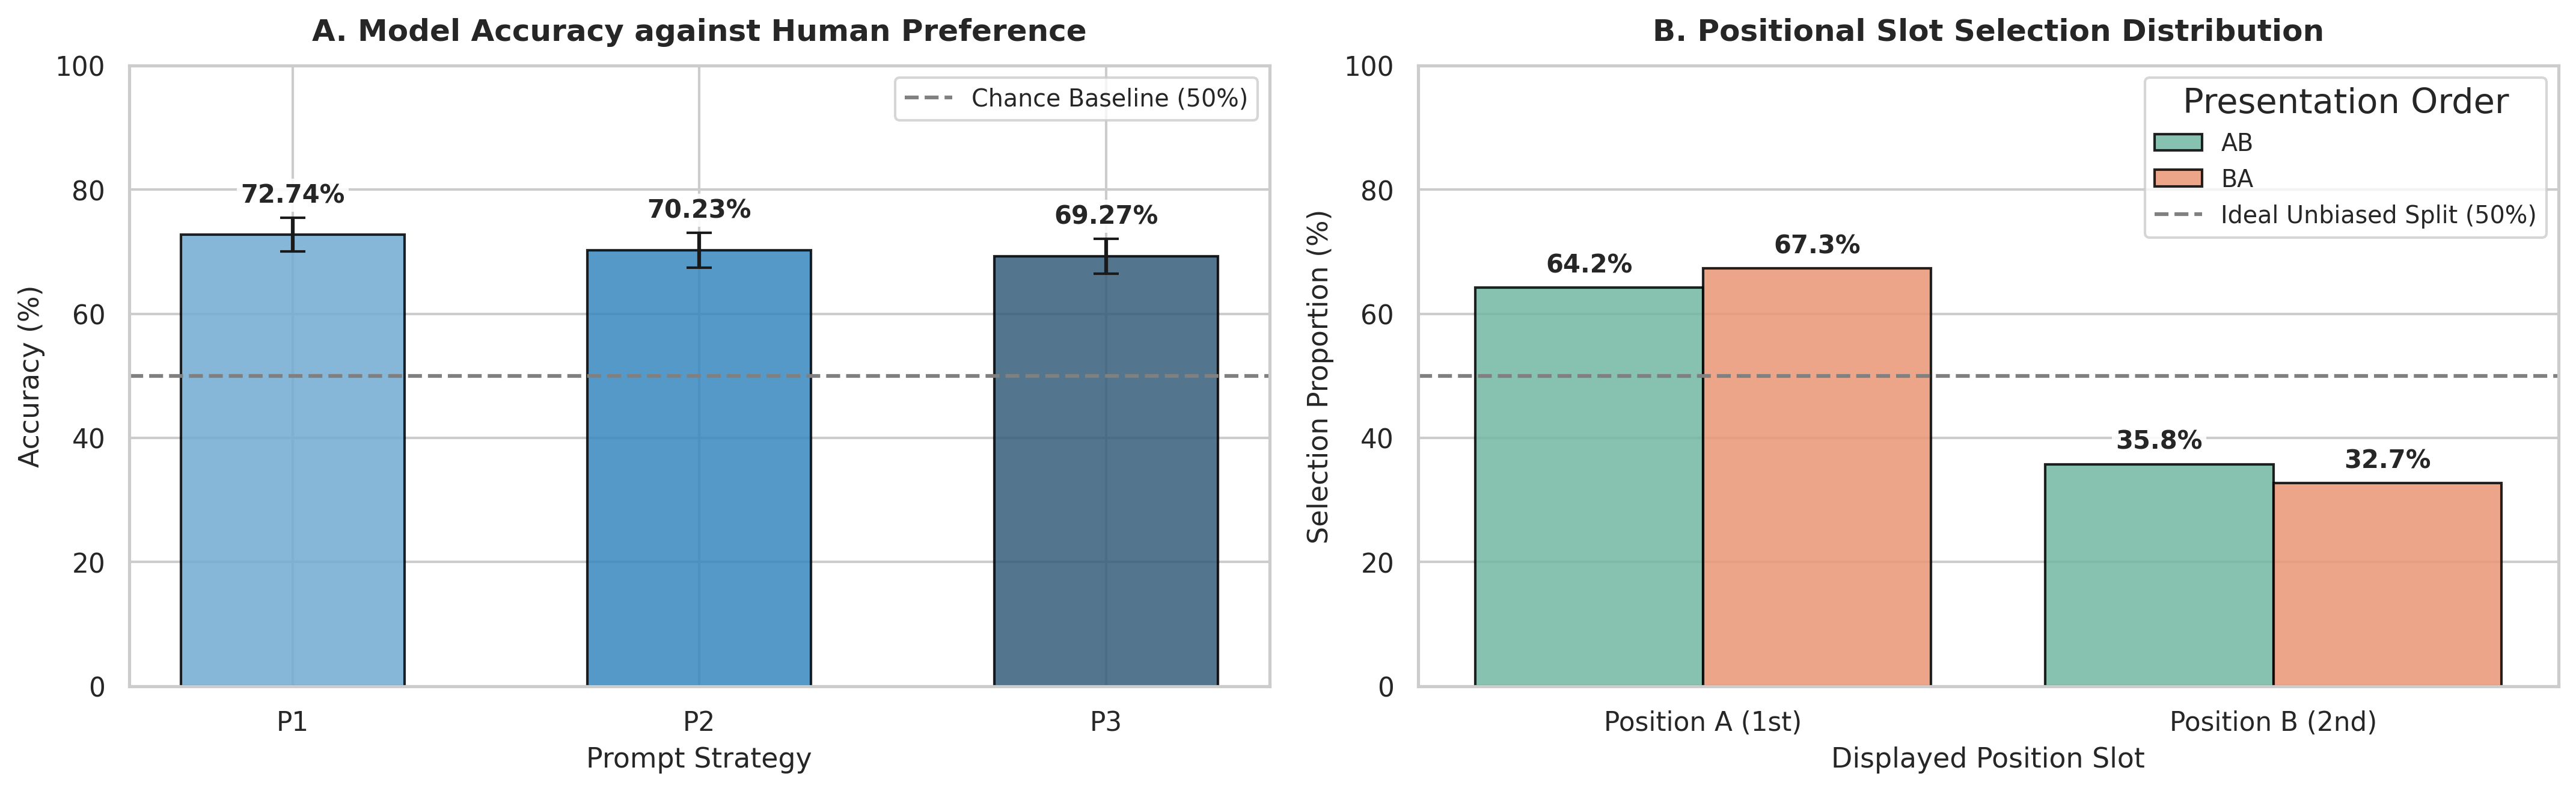

2026-11-28 07:17:47 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_positional_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b
2026-11-28 07:17:47 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_positional_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b
2026-11-28 07:17:48 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_cohen_kappa | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b


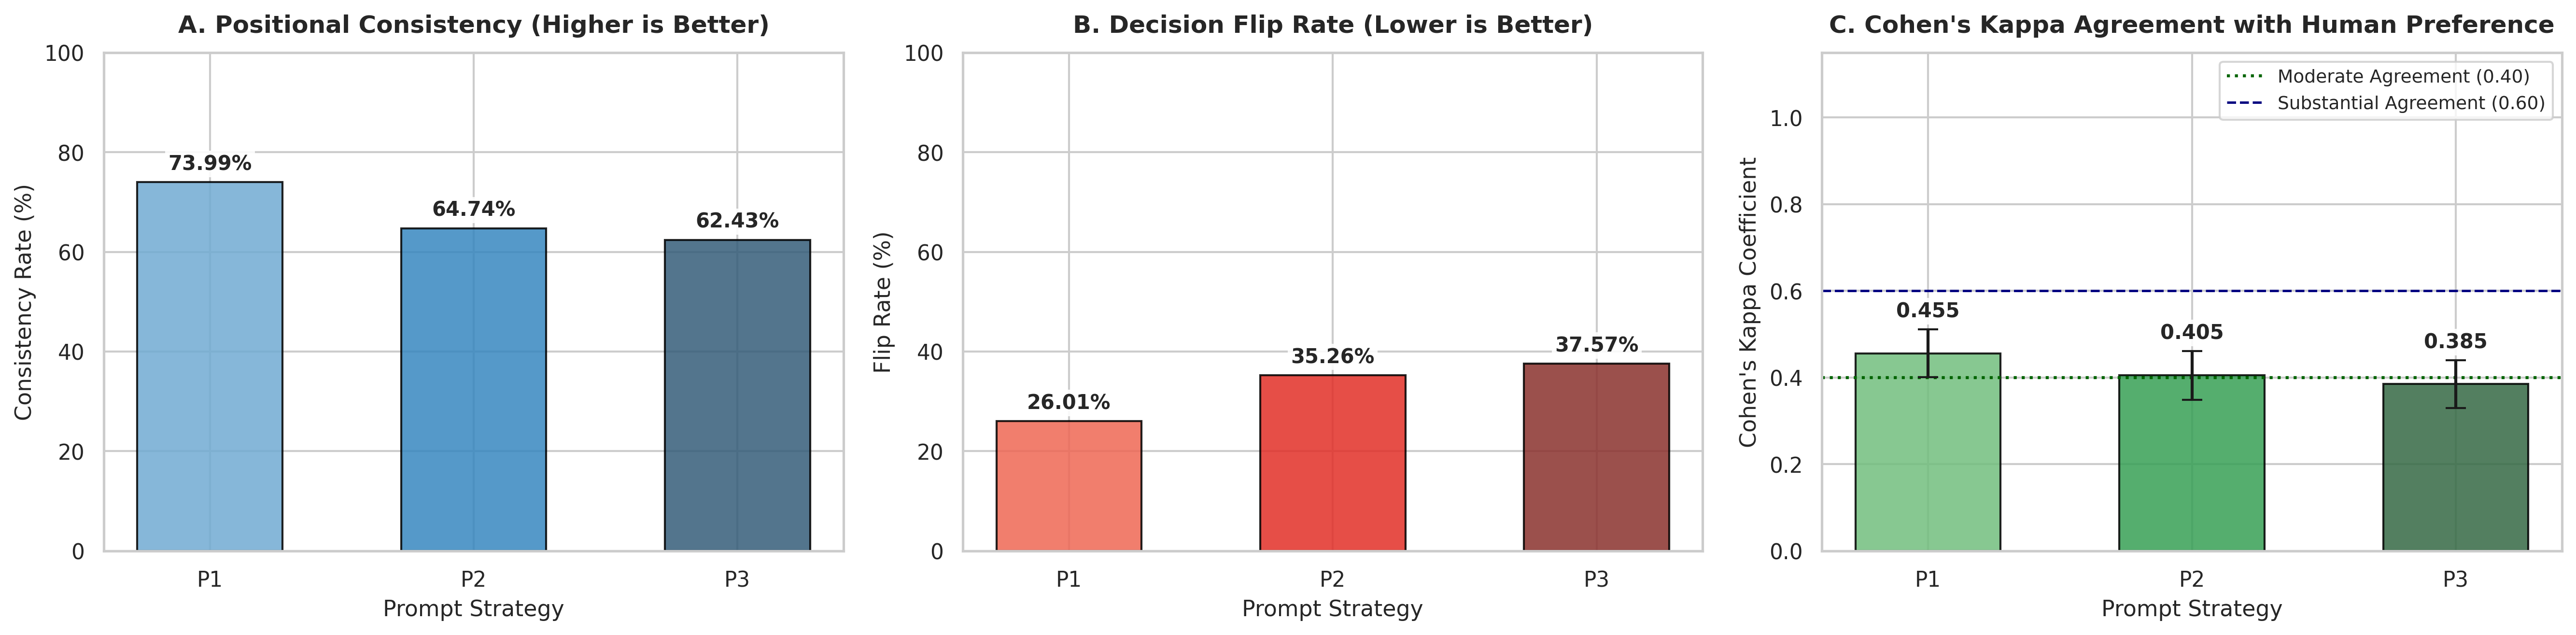

2026-11-28 07:17:49 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_parsing_success_ratio | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b
2026-11-28 07:17:49 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_domain_accuracy | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b


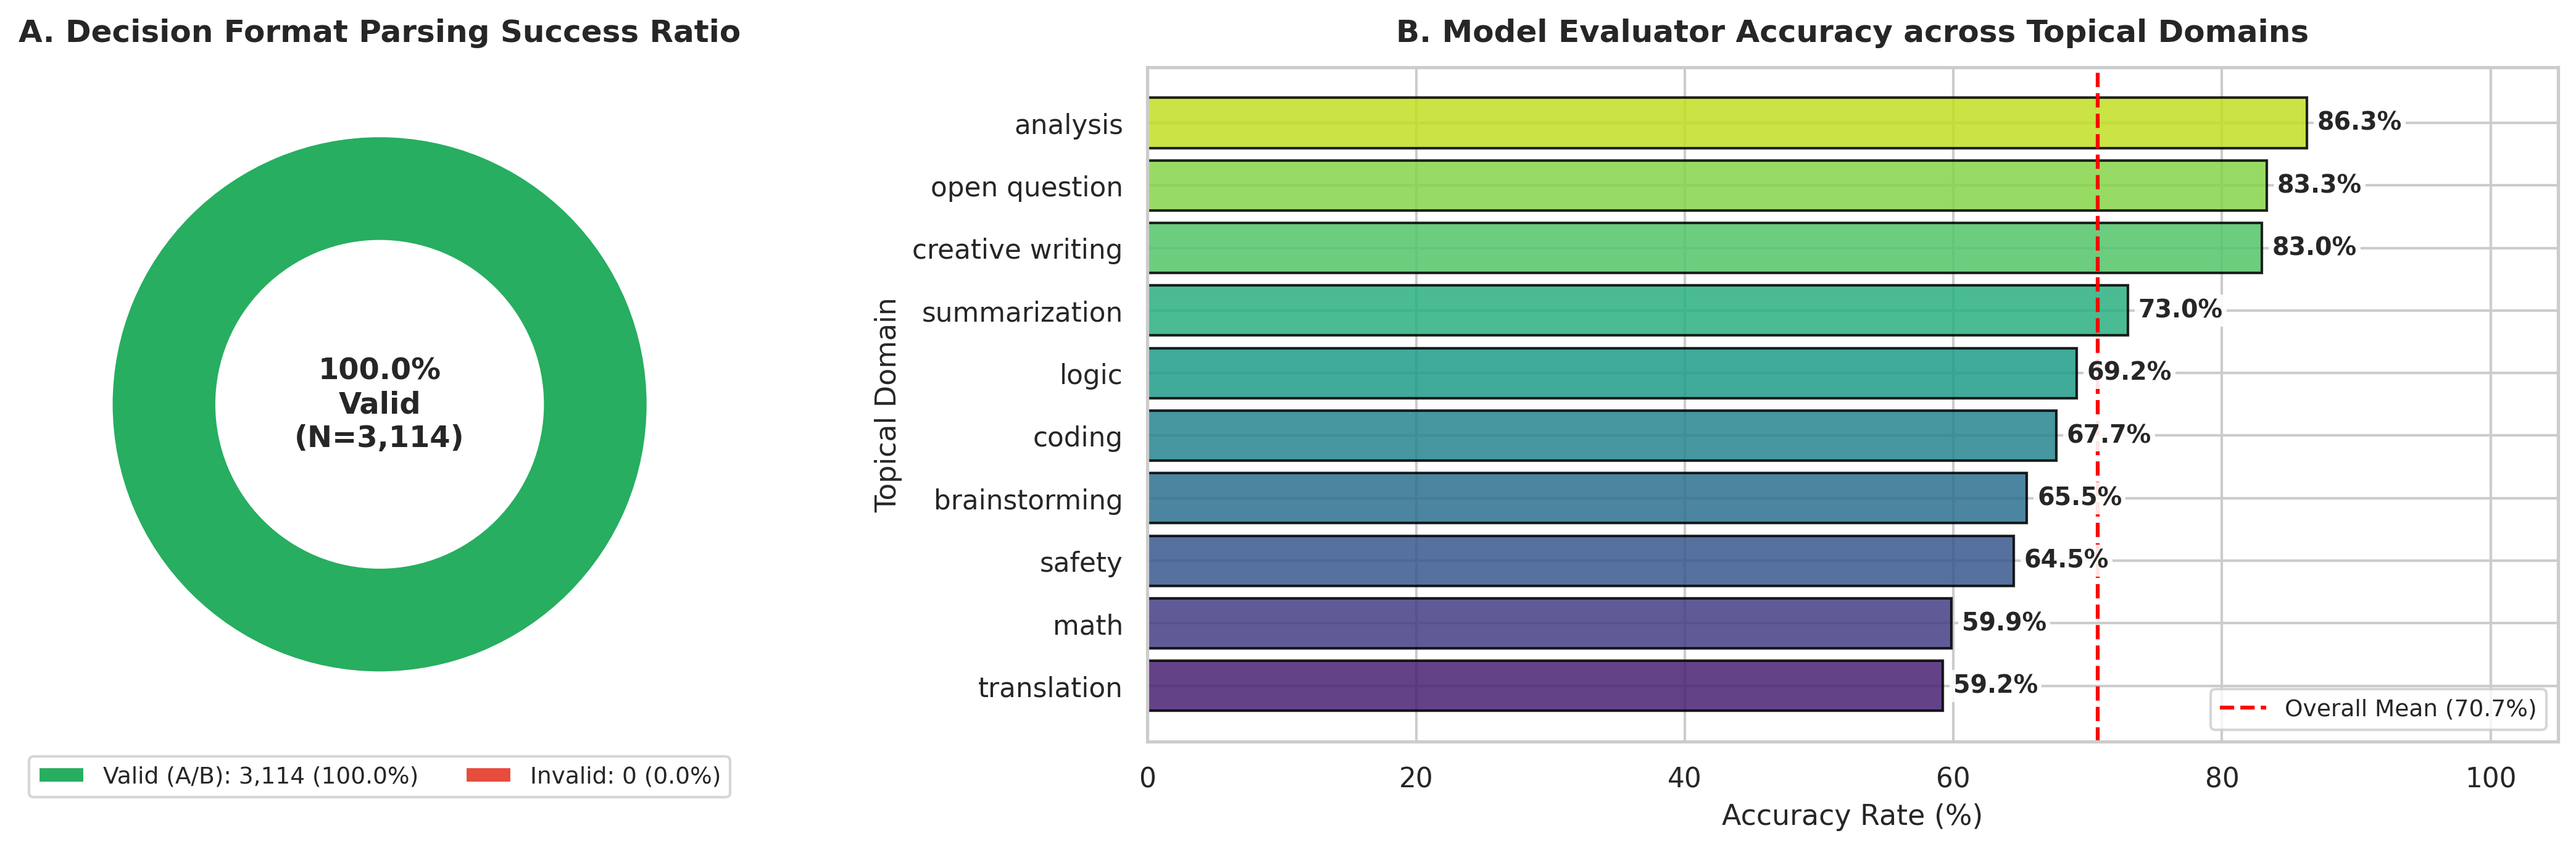

2026-11-28 07:17:50 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_positional_heatmap_p1 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b
2026-11-28 07:17:50 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_positional_heatmap_p2 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b
2026-11-28 07:17:50 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_positional_heatmap_p3 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b


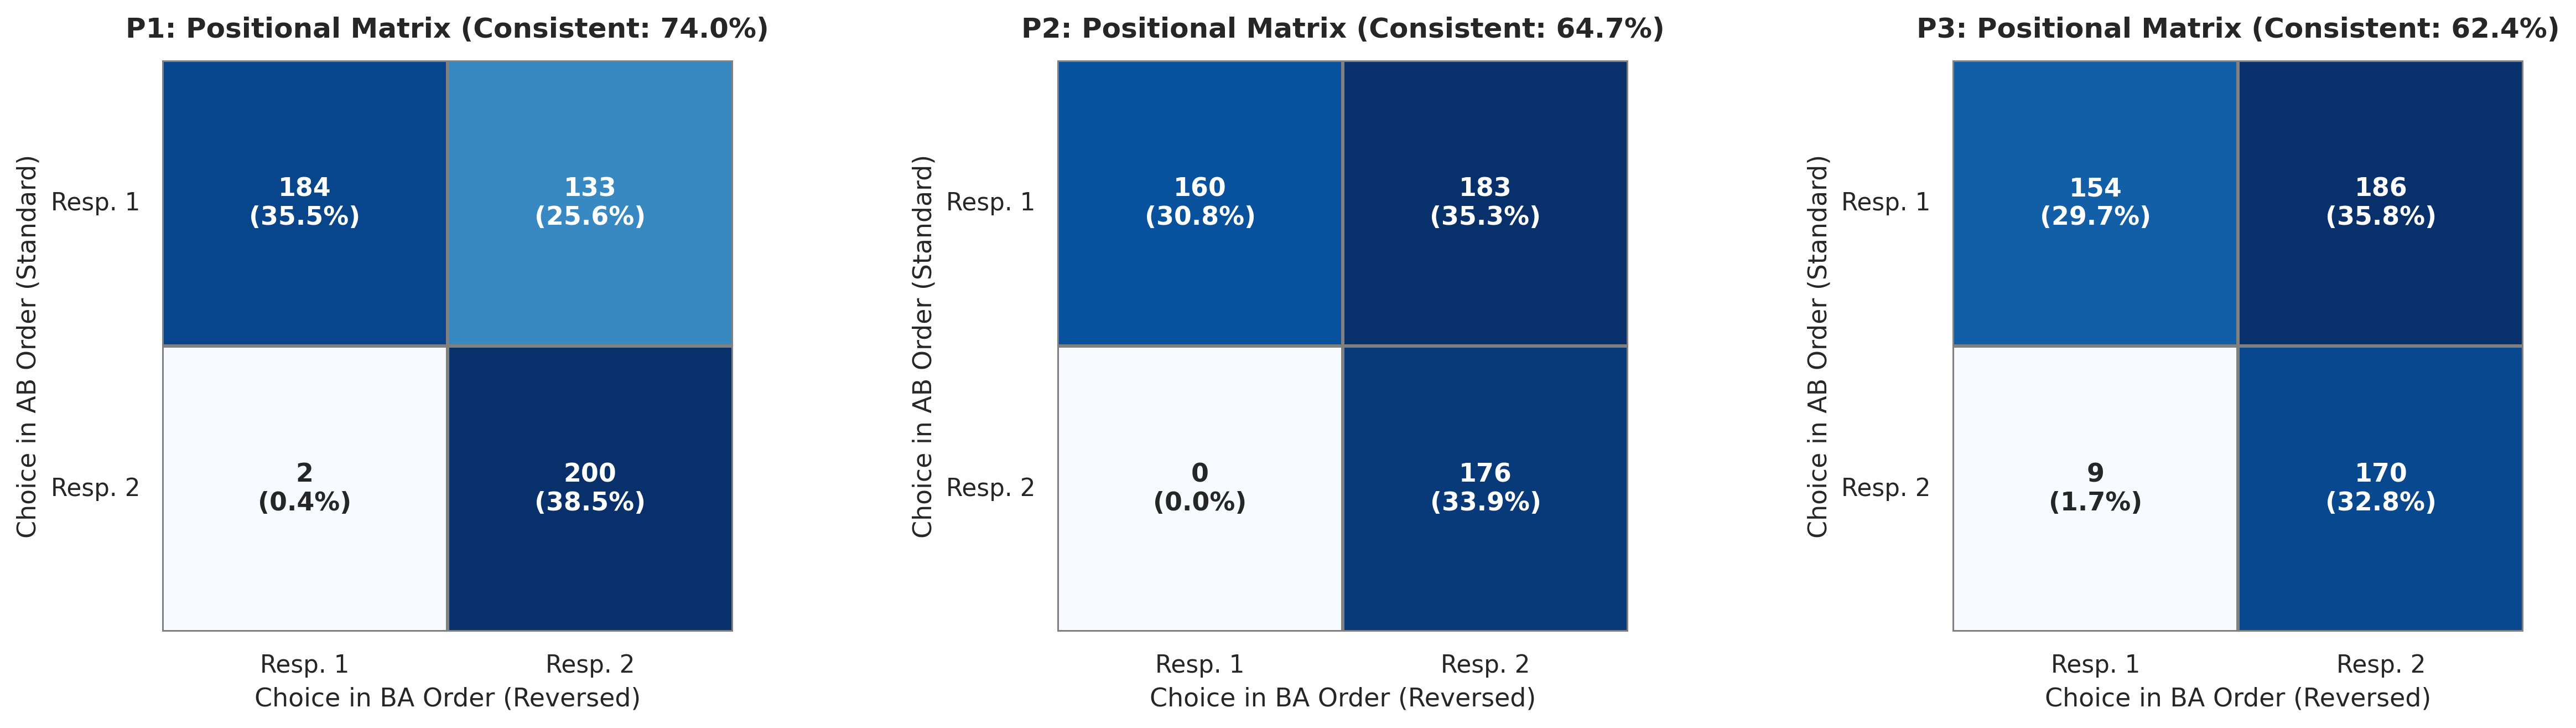

2026-11-28 07:17:51 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_prompt_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b
2026-11-28 07:17:52 | INFO     | llm_exp.qwen3_32b | fig_saved | name=plot_prompt_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b


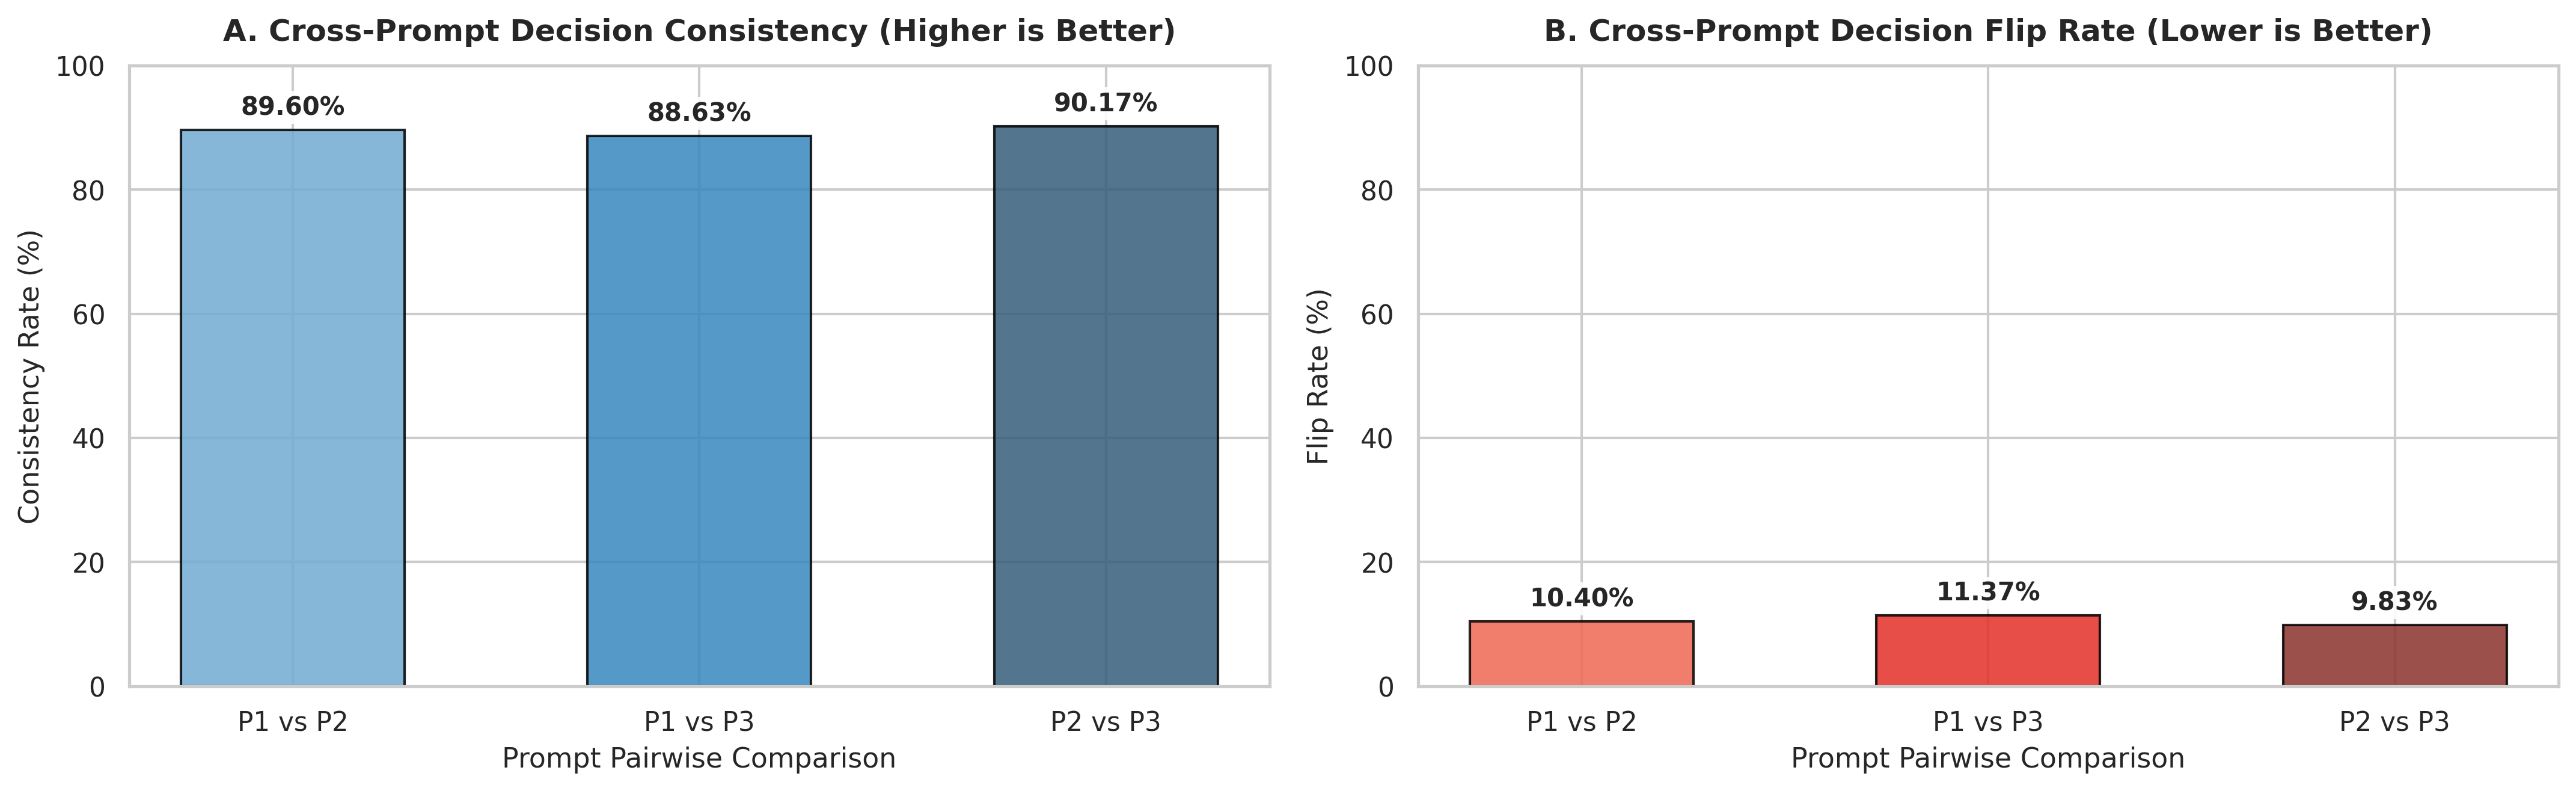

2026-11-28 07:17:52 | INFO     | llm_exp.qwen3_32b | stage_done | model=qwen3_32b | stage=all


0

In [7]:
execute_model_pipeline("qwen3_32b", **PIPELINE_OPTIONS)

### **4.2 GoTo-AI Gemma 3 27B**

GoTo-AI Gemma 3 27B merupakan model 27B dengan spesialisasi bahasa Indonesia yang dimuat melalui loader `gemma3`.

2026-11-28 07:17:52 | INFO     | llm_exp.gemma3_27b_goto | drive_mounted | mount=/content/drive
2026-11-28 07:17:52 | INFO     | llm_exp.gemma3_27b_goto | hf_auth_ok
2026-11-28 07:17:52 | INFO     | llm_exp.gemma3_27b_goto | workspace_ready | root=/content/drive/MyDrive/LLMReliabilityEXP | cache=/content/models
2026-11-28 07:17:52 | INFO     | llm_exp.gemma3_27b_goto | log_init | run_id=gemma3_27b_goto_all_20261128_071752 | tz=Asia/Jakarta | path=/content/drive/MyDrive/LLMReliabilityEXP/logs/2026-11-28/gemma3_27b_goto_all_20261128_071752.log
2026-11-28 07:17:52 | INFO     | llm_exp.gemma3_27b_goto | schema_ok | rows=519 | cols=10
2026-11-28 07:17:52 | INFO     | llm_exp.gemma3_27b_goto | dataset_cache_hit | split=eval | rows=519 | path=/content/drive/MyDrive/LLMReliabilityEXP/data/processed/indopref_eval_stratified.parquet
2026-11-28 07:17:52 | INFO     | llm_exp.gemma3_27b_goto | resume_status | model=gemma3_27b_goto | total=3114 | done=3114 | pending=0
2026-11-28 07:17:52 | INFO     

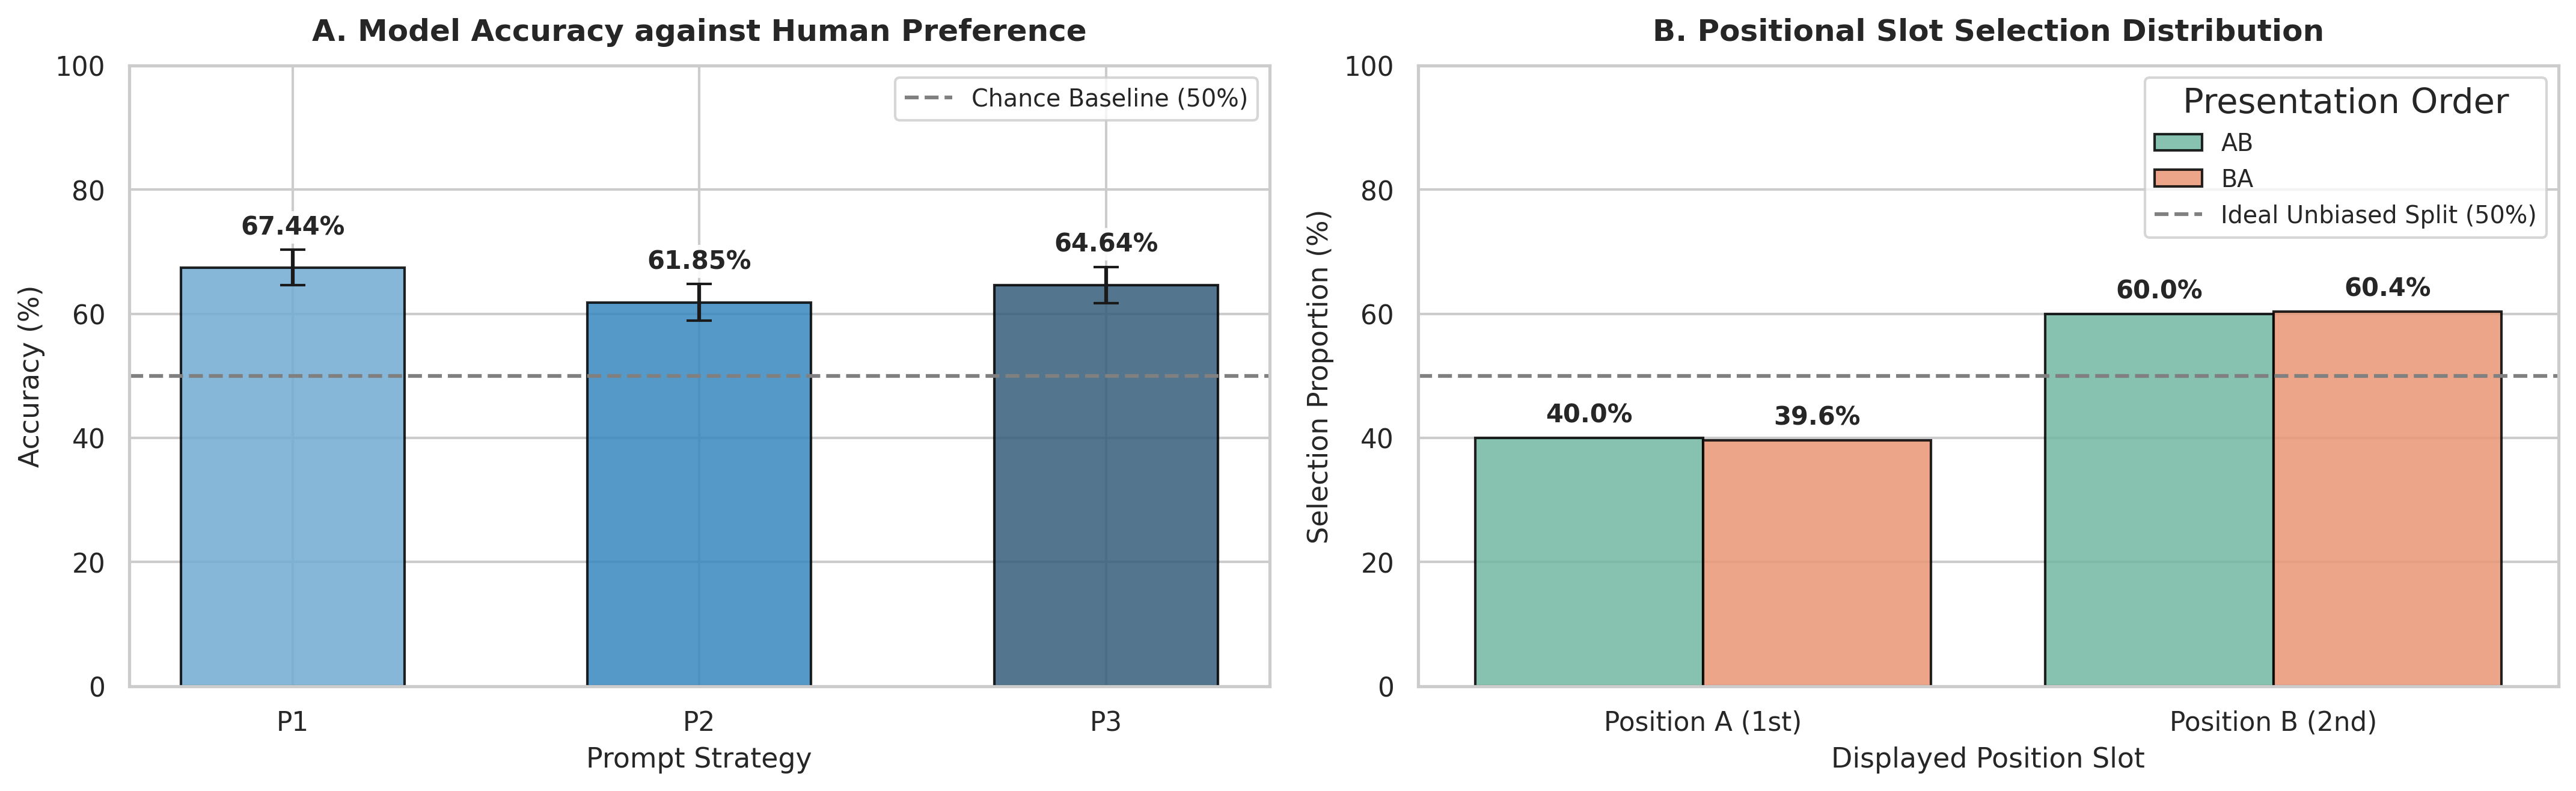

2026-11-28 07:17:56 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_positional_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto
2026-11-28 07:17:57 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_positional_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto
2026-11-28 07:17:57 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_cohen_kappa | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto


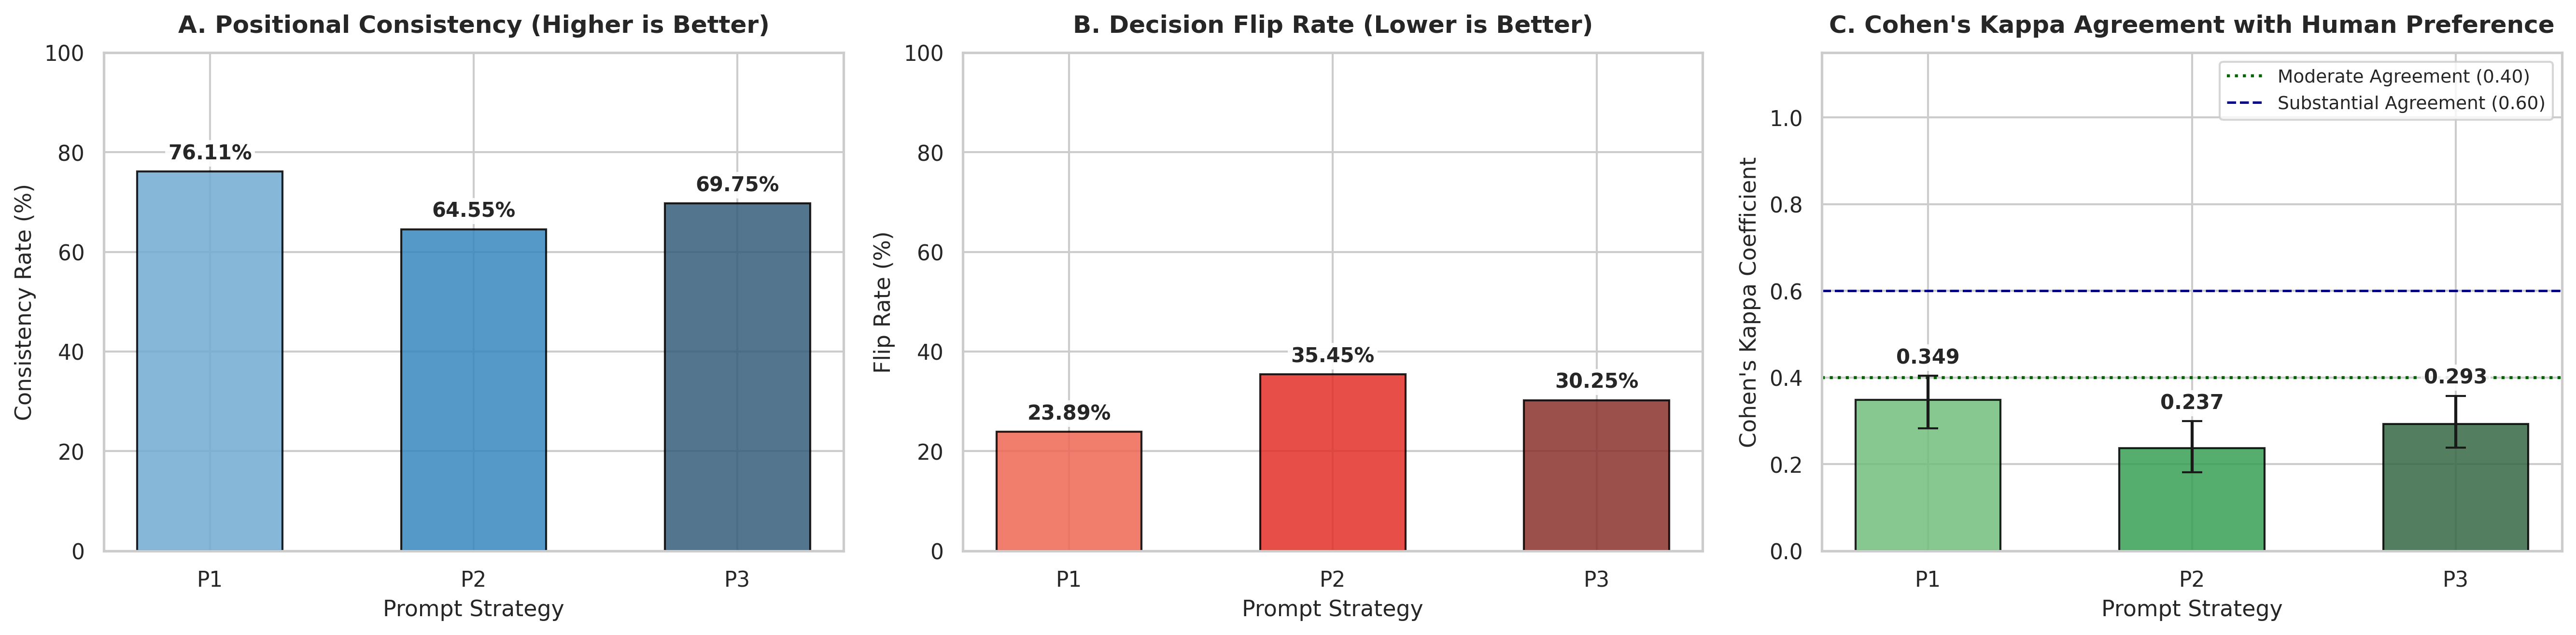

2026-11-28 07:17:58 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_parsing_success_ratio | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto
2026-11-28 07:17:58 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_domain_accuracy | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto


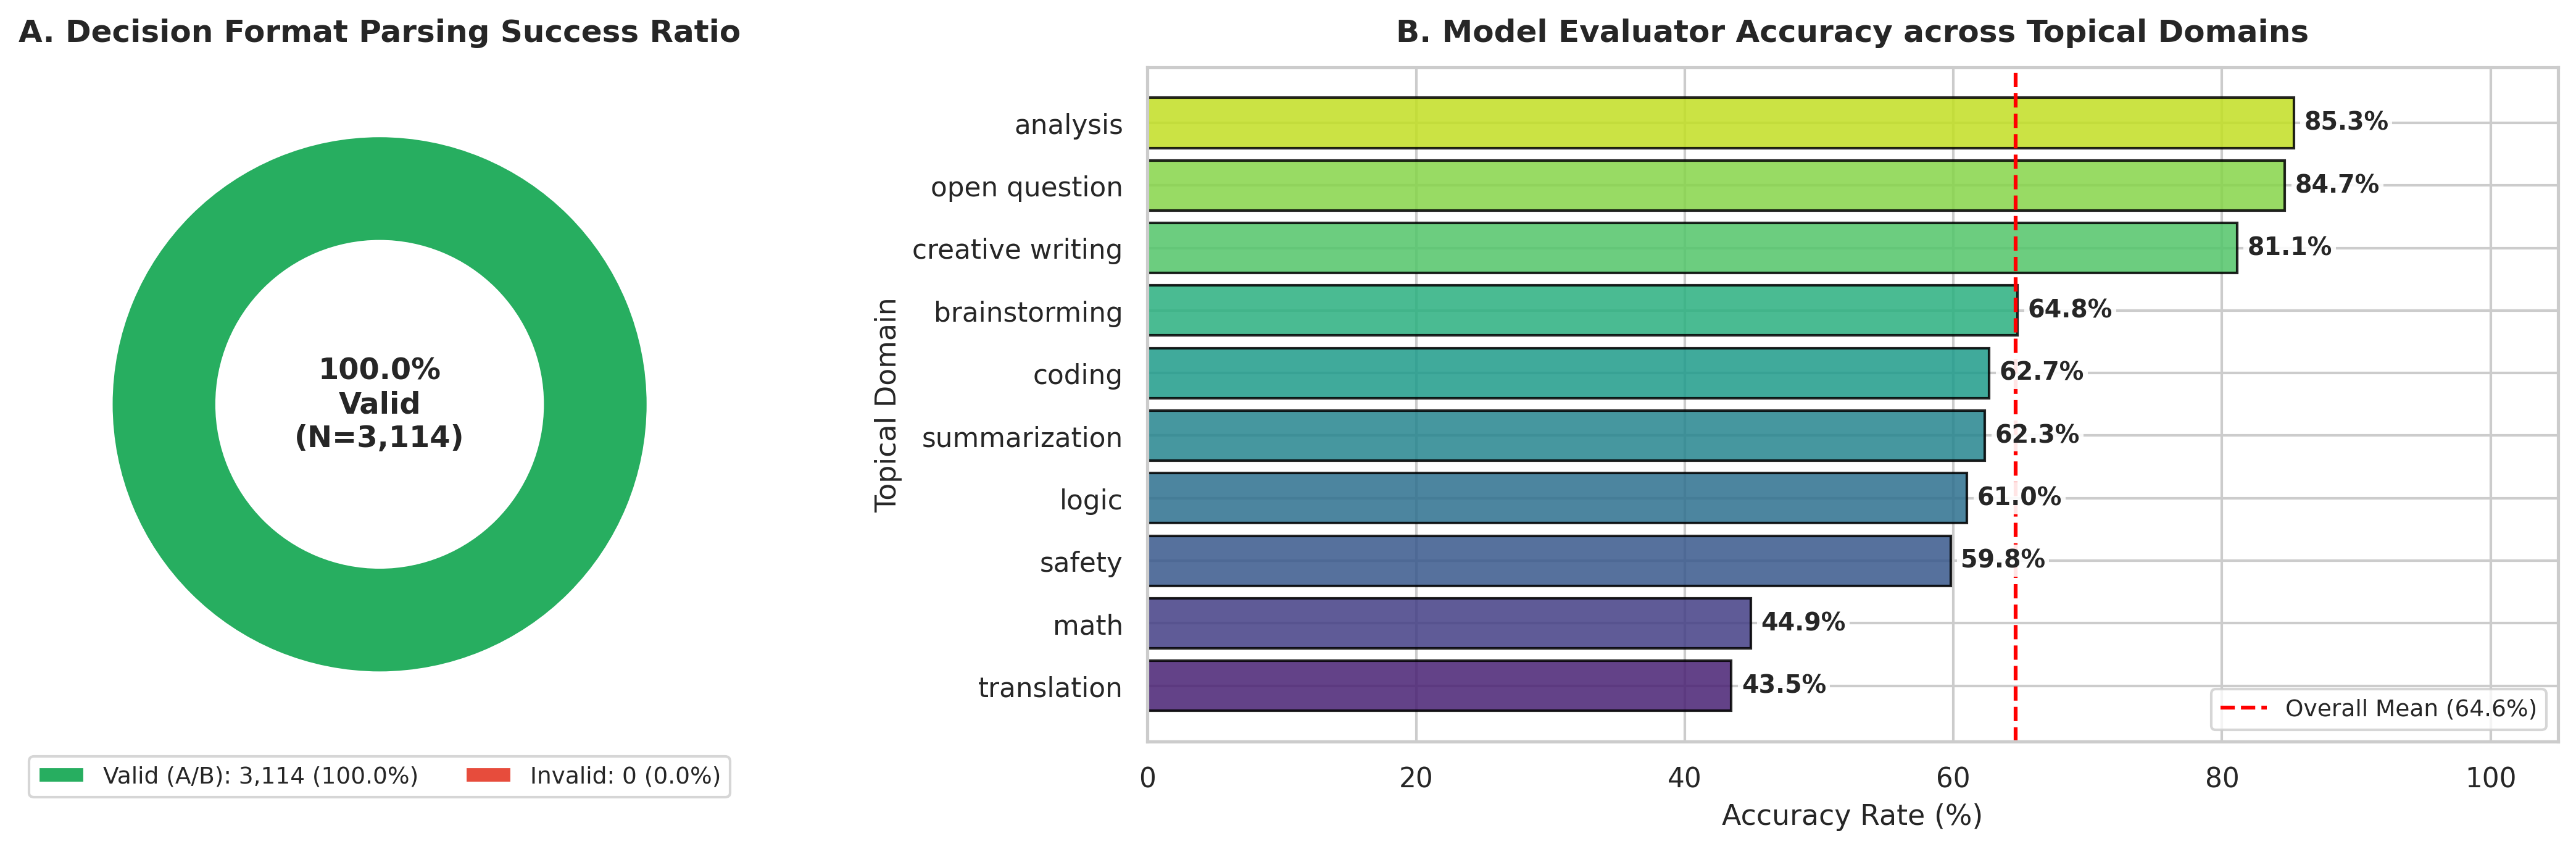

2026-11-28 07:17:59 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_positional_heatmap_p1 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto
2026-11-28 07:18:00 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_positional_heatmap_p2 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto
2026-11-28 07:18:00 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_positional_heatmap_p3 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto


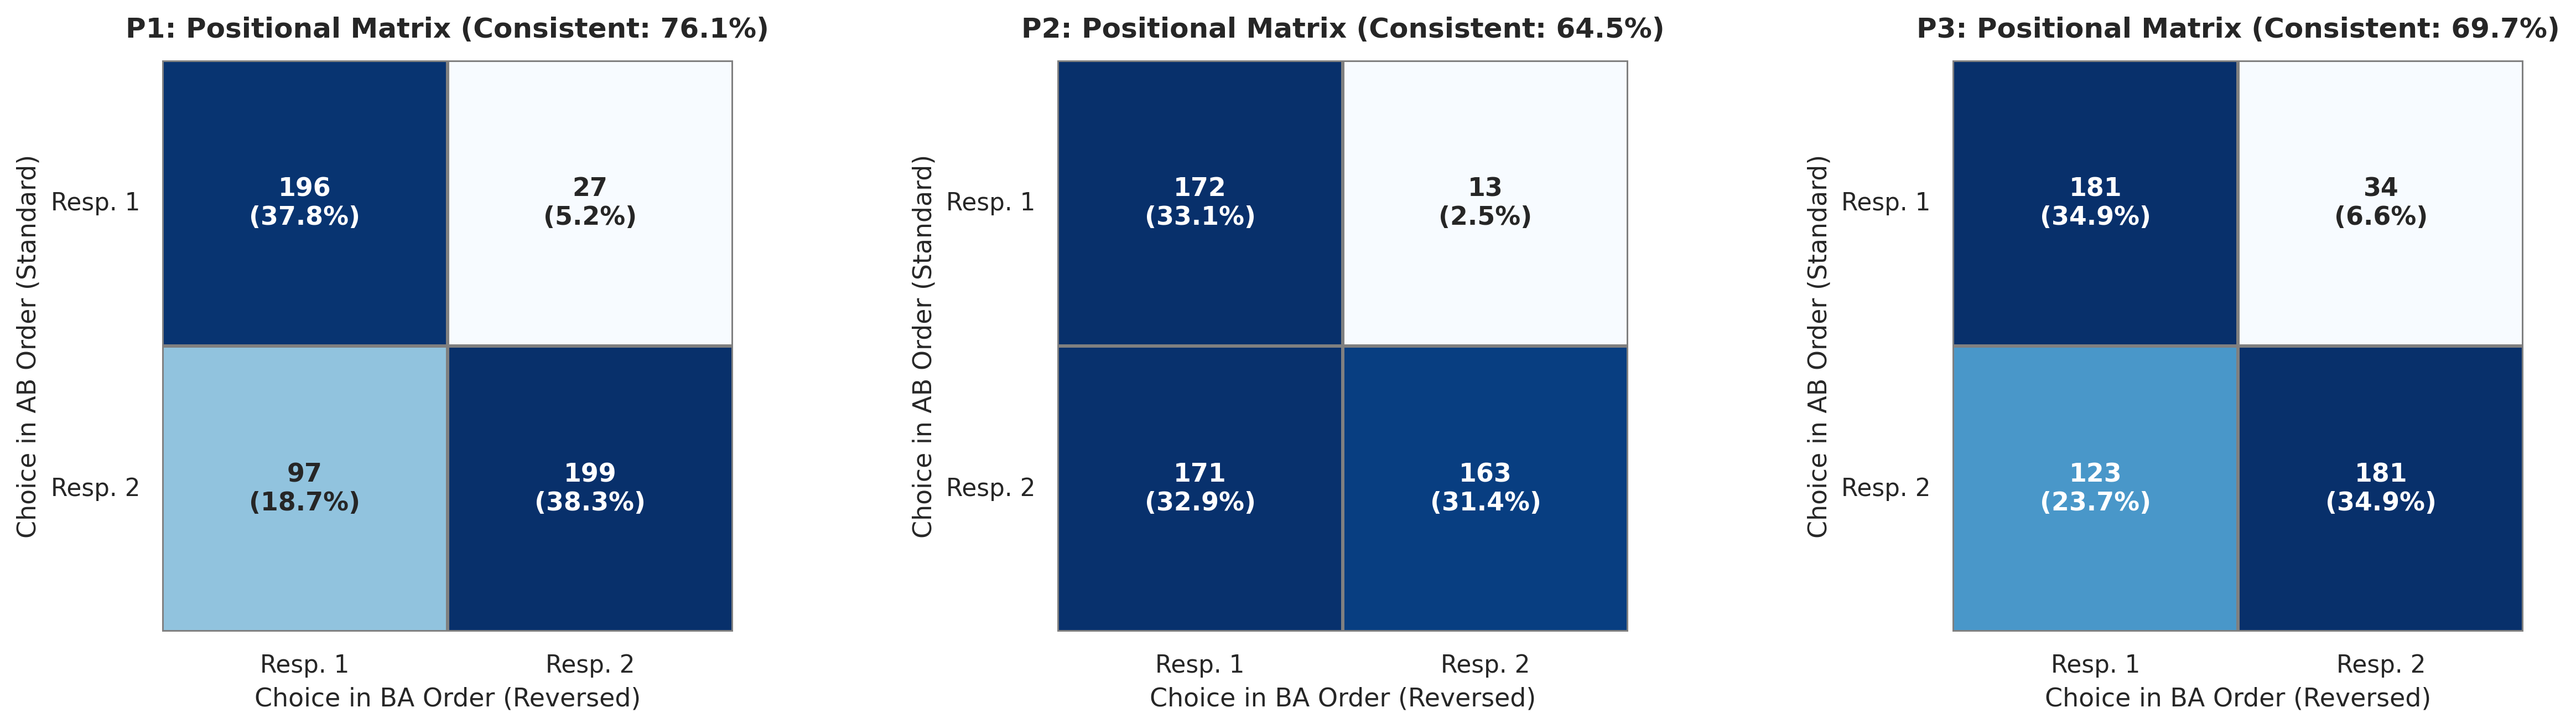

2026-11-28 07:18:01 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_prompt_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto
2026-11-28 07:18:01 | INFO     | llm_exp.gemma3_27b_goto | fig_saved | name=plot_prompt_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/gemma3_27b_goto


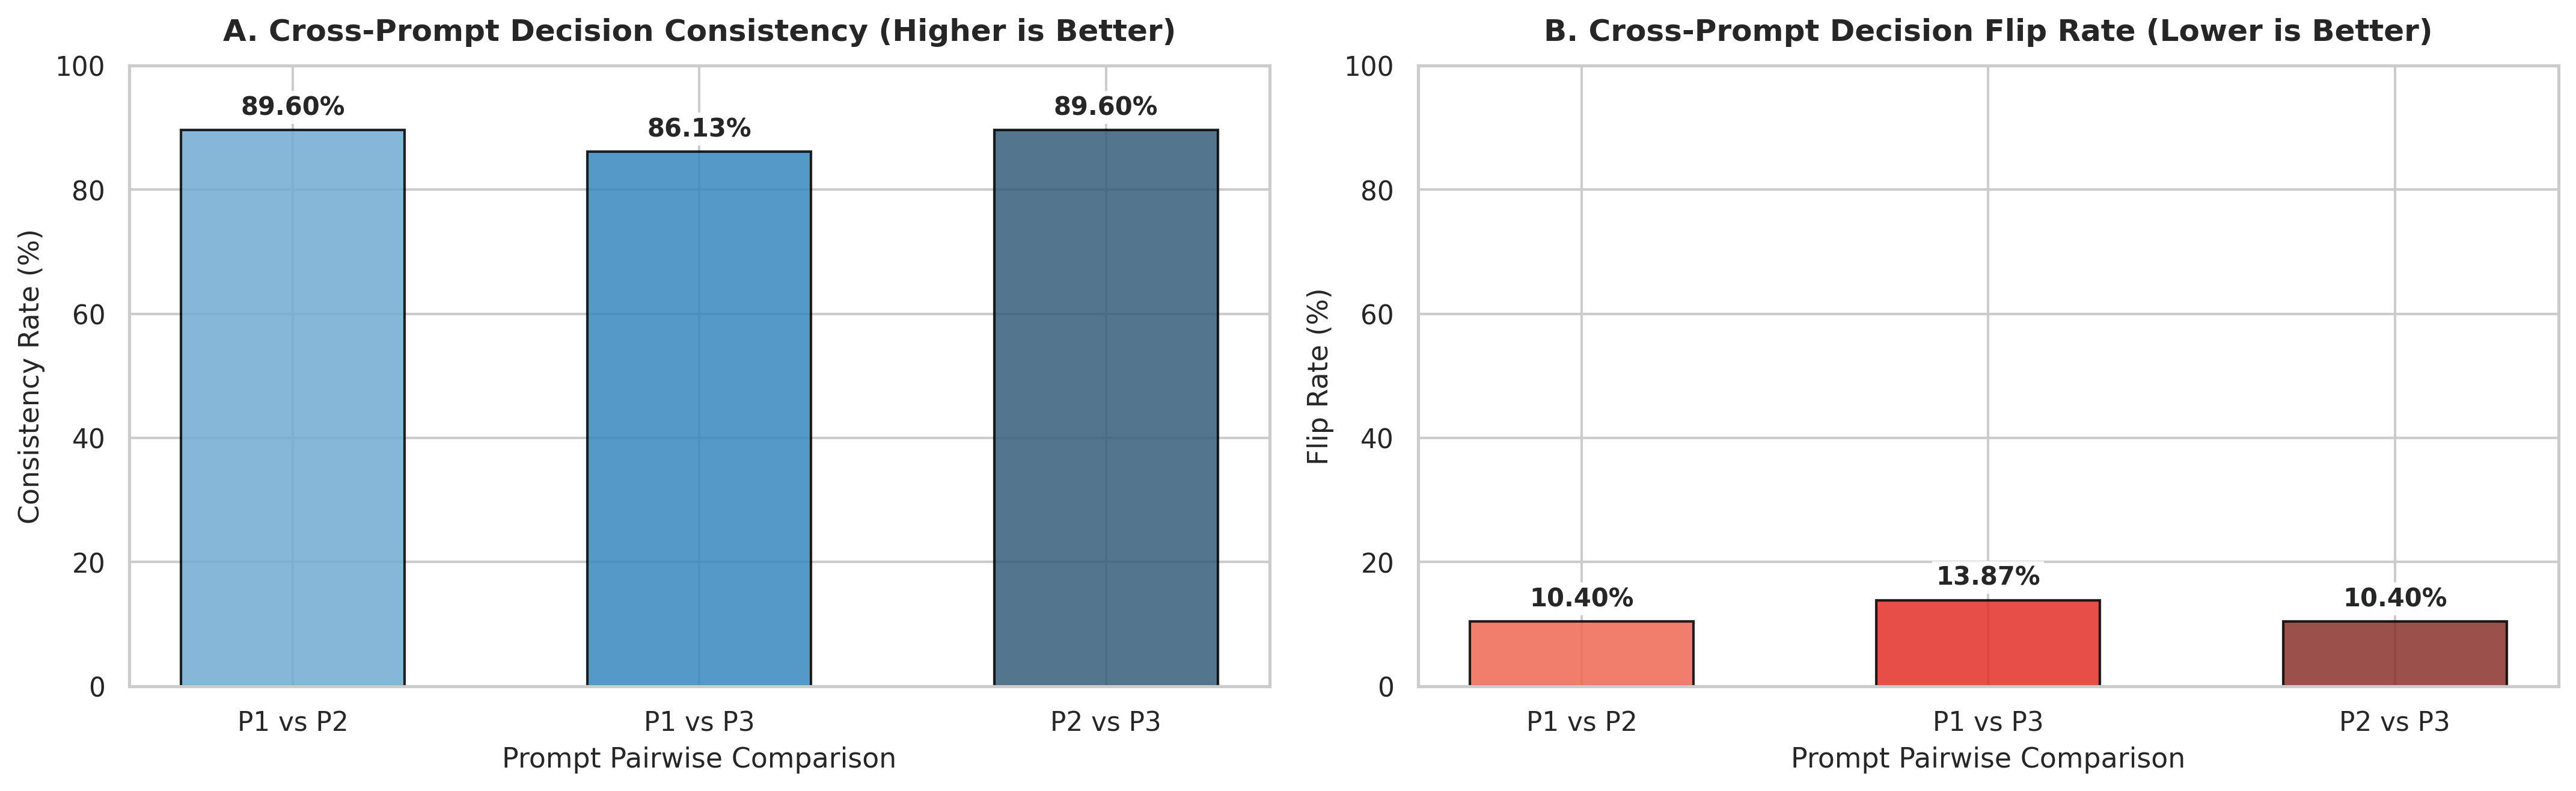

2026-11-28 07:18:01 | INFO     | llm_exp.gemma3_27b_goto | stage_done | model=gemma3_27b_goto | stage=all


0

In [8]:
execute_model_pipeline("gemma3_27b_goto", **PIPELINE_OPTIONS)

### **4.3 Aya Expanse 32B**

Aya Expanse 32B merupakan model multibahasa 32B dengan loader `causal_lm`. Repositori ini berstatus *gated*, sehingga token Hugging Face harus memiliki izin akses terlebih dahulu.

2026-11-28 07:18:01 | INFO     | llm_exp.aya_expanse_32b | drive_mounted | mount=/content/drive
2026-11-28 07:18:02 | INFO     | llm_exp.aya_expanse_32b | hf_auth_ok
2026-11-28 07:18:02 | INFO     | llm_exp.aya_expanse_32b | workspace_ready | root=/content/drive/MyDrive/LLMReliabilityEXP | cache=/content/models
2026-11-28 07:18:02 | INFO     | llm_exp.aya_expanse_32b | log_init | run_id=aya_expanse_32b_all_20261128_071802 | tz=Asia/Jakarta | path=/content/drive/MyDrive/LLMReliabilityEXP/logs/2026-11-28/aya_expanse_32b_all_20261128_071802.log
2026-11-28 07:18:02 | INFO     | llm_exp.aya_expanse_32b | schema_ok | rows=519 | cols=10
2026-11-28 07:18:02 | INFO     | llm_exp.aya_expanse_32b | dataset_cache_hit | split=eval | rows=519 | path=/content/drive/MyDrive/LLMReliabilityEXP/data/processed/indopref_eval_stratified.parquet
2026-11-28 07:18:02 | INFO     | llm_exp.aya_expanse_32b | resume_status | model=aya_expanse_32b | total=3114 | done=3114 | pending=0
2026-11-28 07:18:02 | INFO     

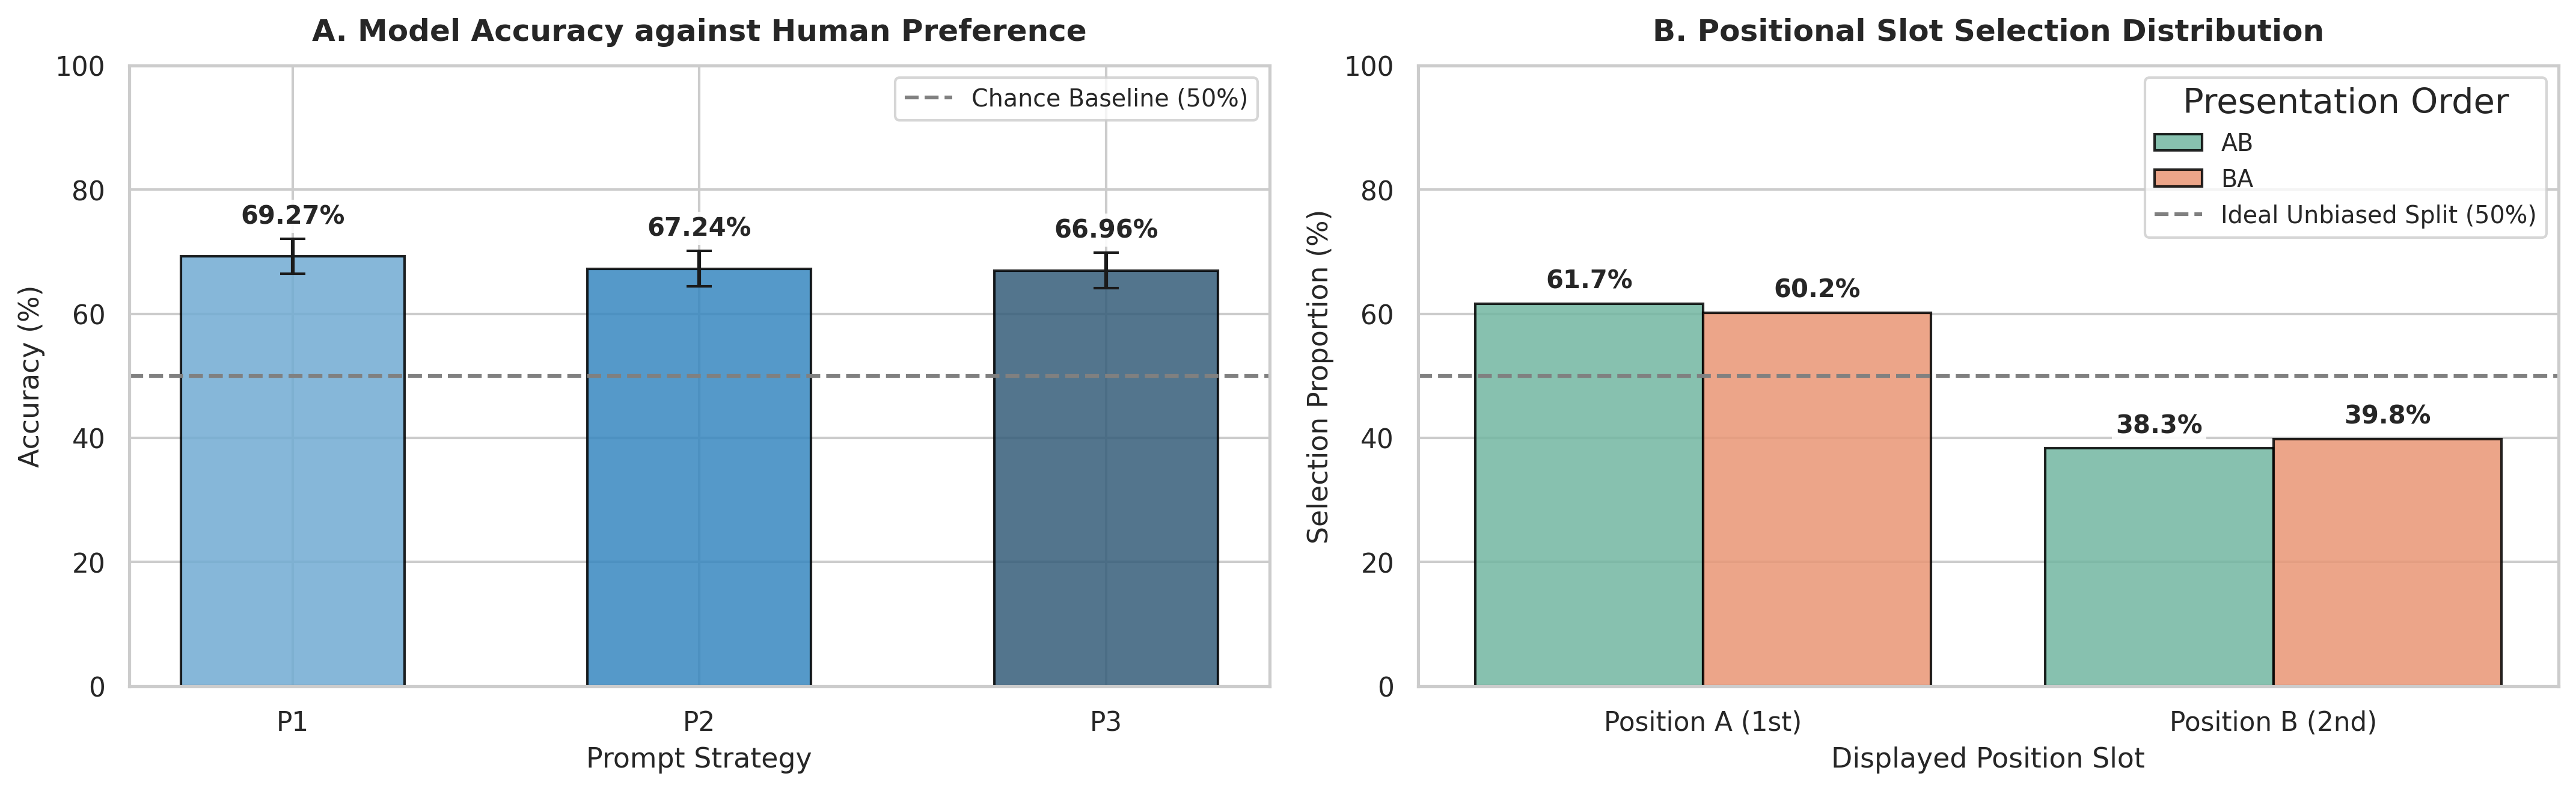

2026-11-28 07:18:06 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_positional_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b
2026-11-28 07:18:06 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_positional_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b
2026-11-28 07:18:06 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_cohen_kappa | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b


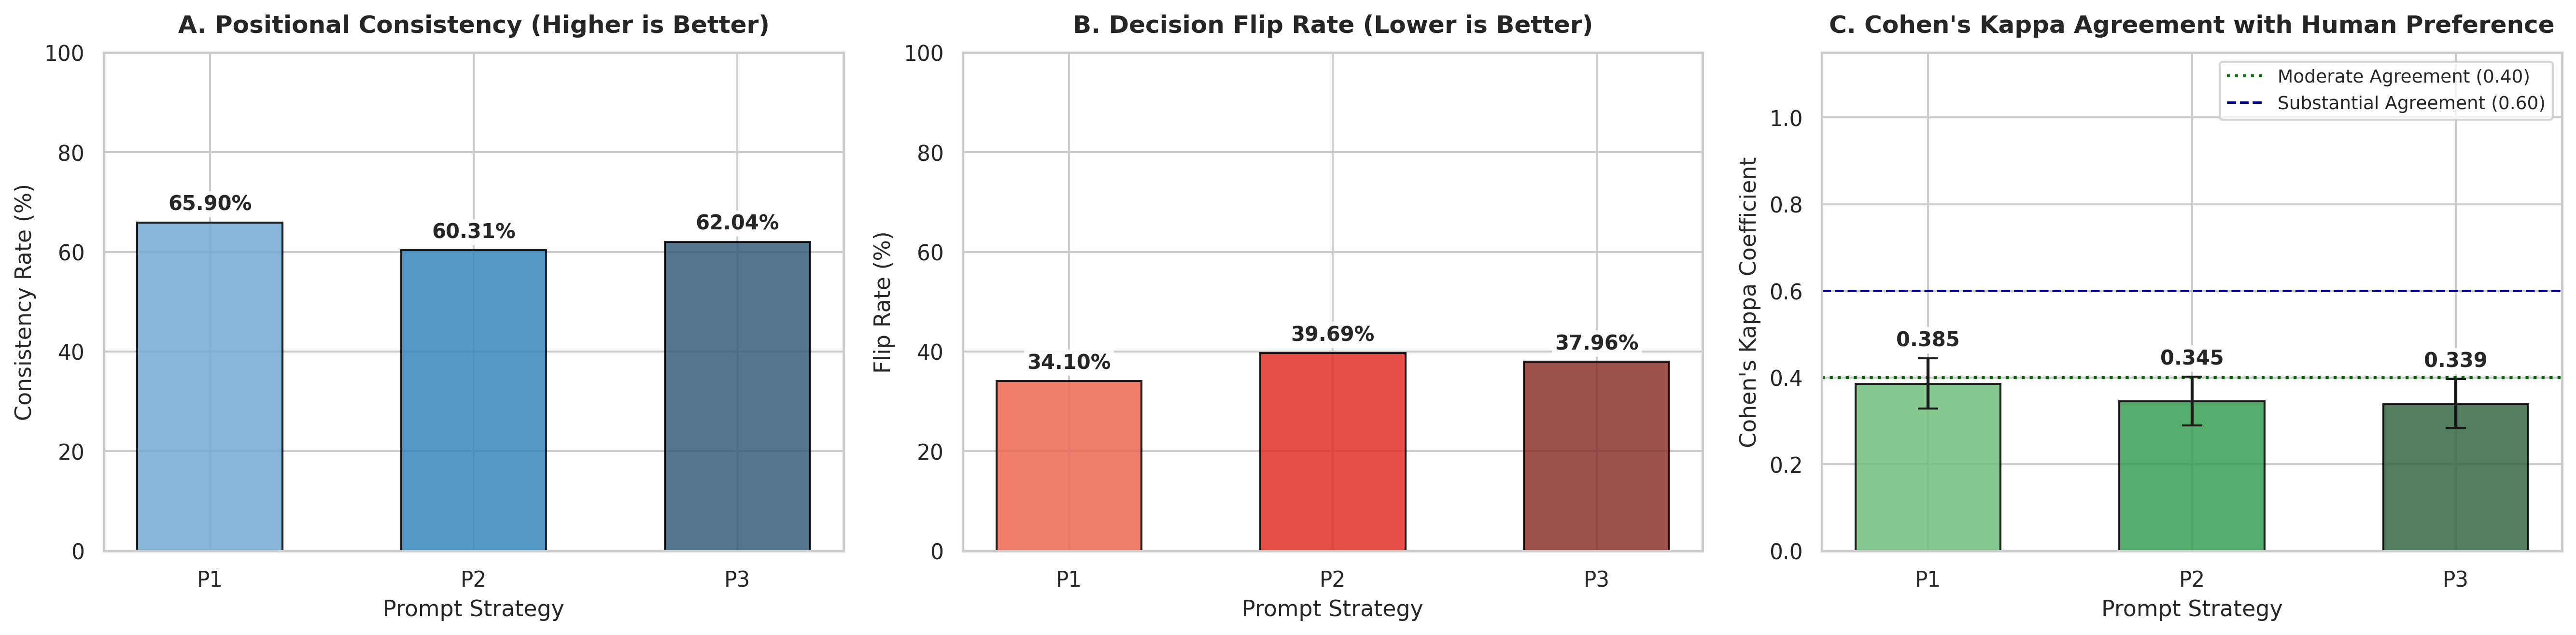

2026-11-28 07:18:07 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_parsing_success_ratio | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b
2026-11-28 07:18:08 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_domain_accuracy | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b


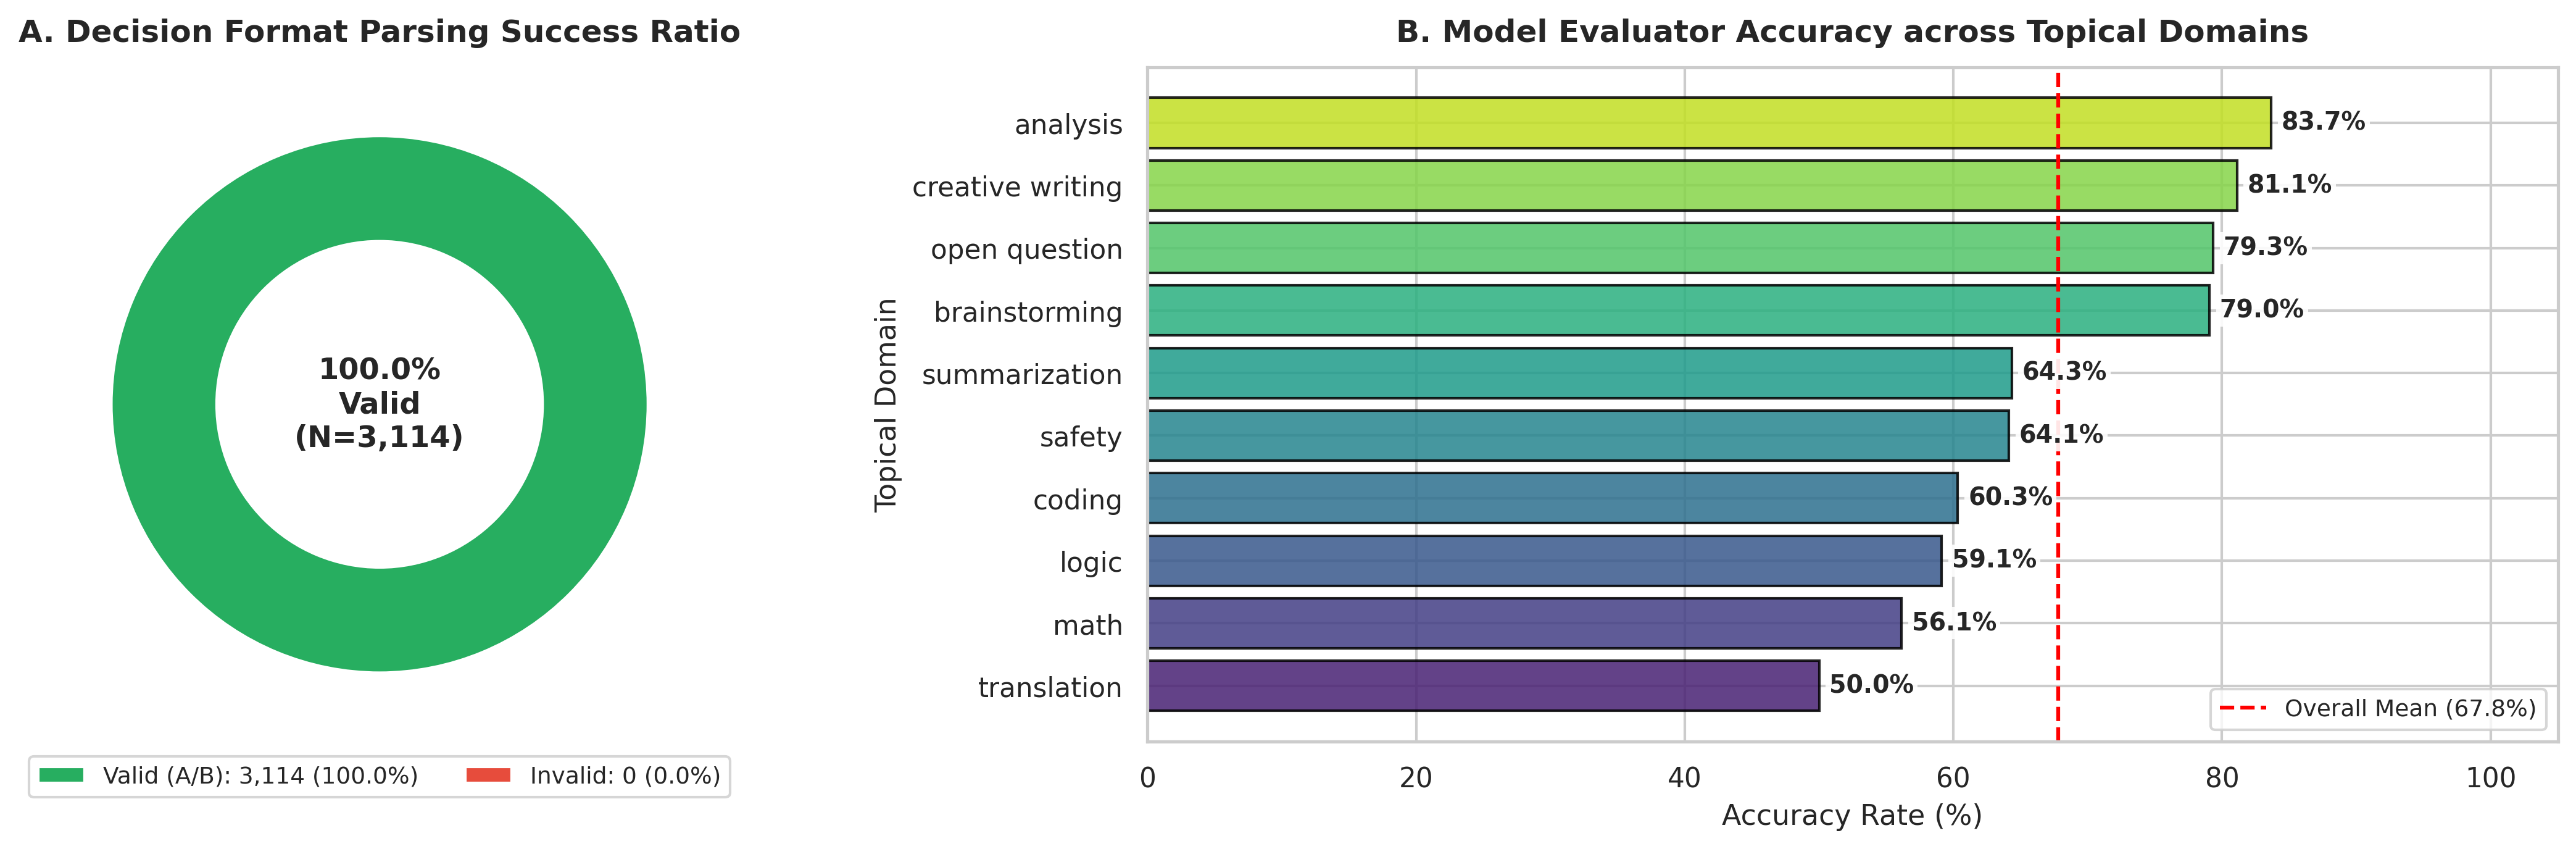

2026-11-28 07:18:09 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_positional_heatmap_p1 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b
2026-11-28 07:18:09 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_positional_heatmap_p2 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b
2026-11-28 07:18:09 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_positional_heatmap_p3 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b


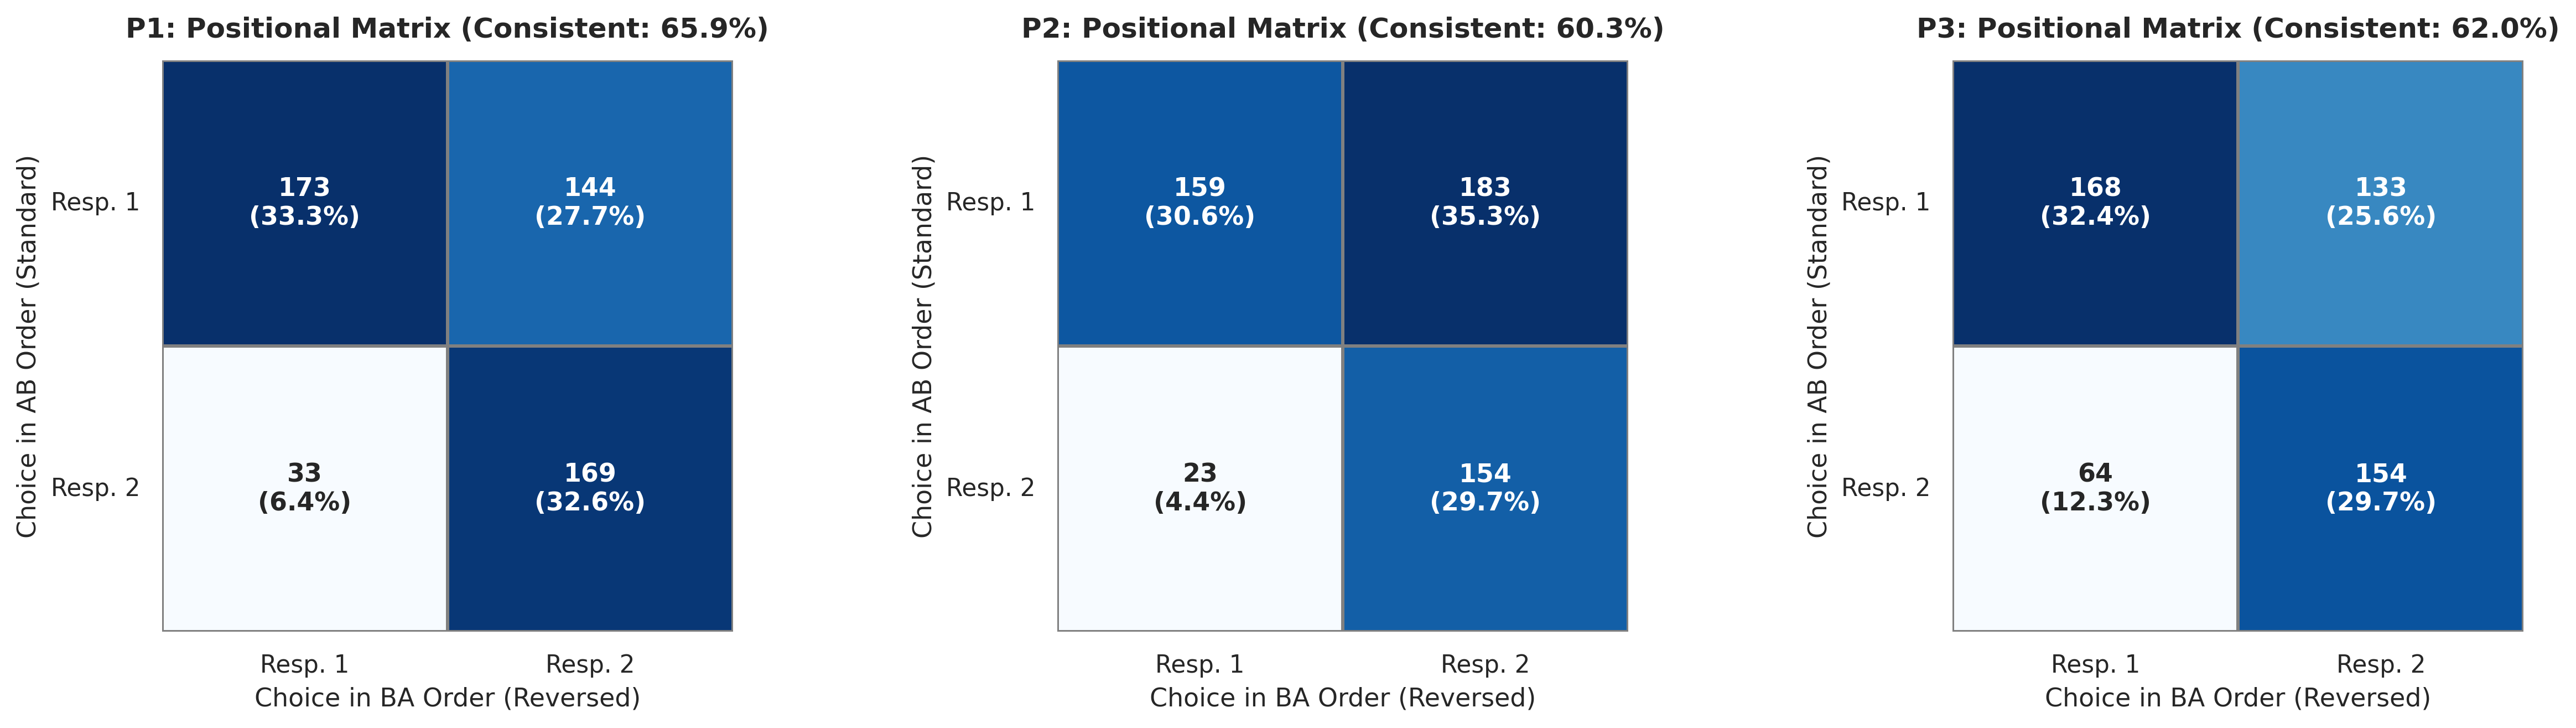

2026-11-28 07:18:10 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_prompt_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b
2026-11-28 07:18:10 | INFO     | llm_exp.aya_expanse_32b | fig_saved | name=plot_prompt_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/aya_expanse_32b


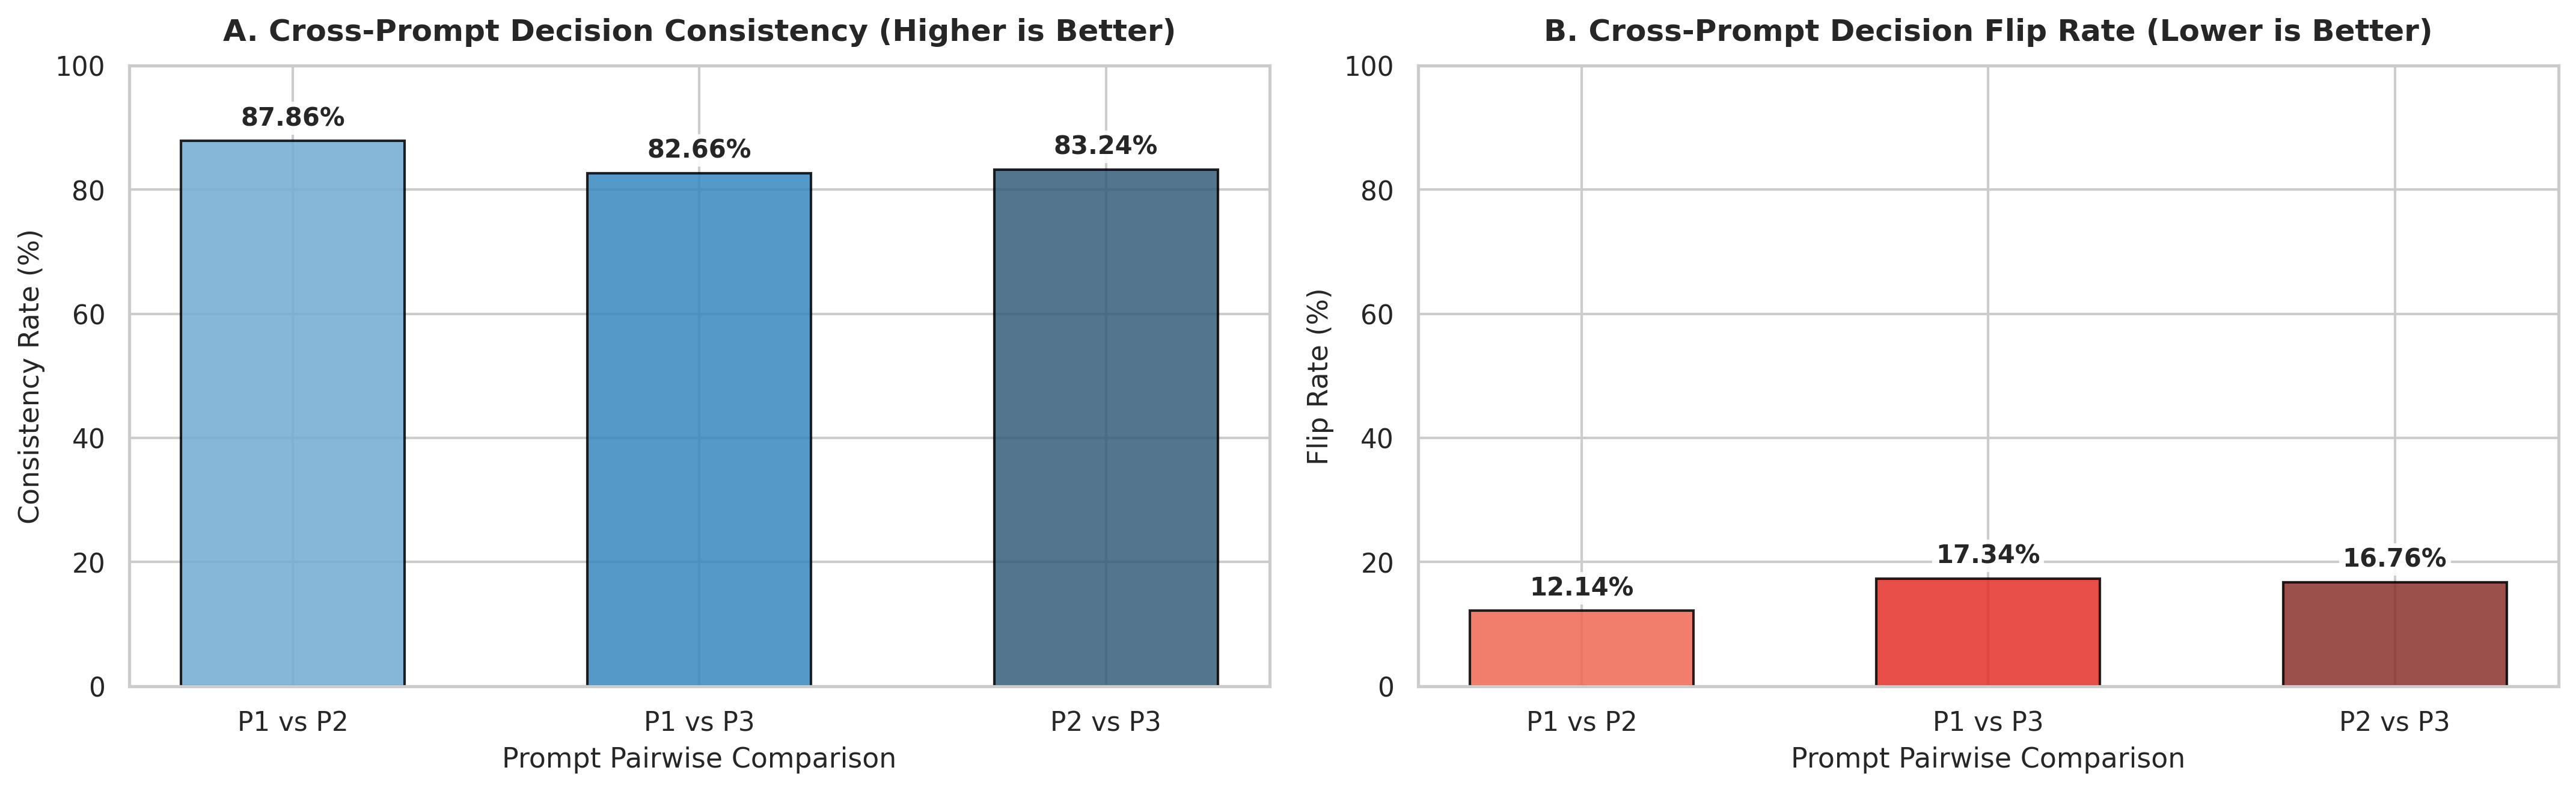

2026-11-28 07:18:11 | INFO     | llm_exp.aya_expanse_32b | stage_done | model=aya_expanse_32b | stage=all


0

In [9]:
execute_model_pipeline("aya_expanse_32b", **PIPELINE_OPTIONS)

### **4.4 Mistral Small 3.1 24B**

Mistral Small 3.1 24B difokuskan pada kemampuan instruction-following 24B dengan loader `mistral3`.

2026-11-28 07:18:11 | INFO     | llm_exp.mistral_small_3_1_24b | drive_mounted | mount=/content/drive
2026-11-28 07:18:11 | INFO     | llm_exp.mistral_small_3_1_24b | hf_auth_ok
2026-11-28 07:18:11 | INFO     | llm_exp.mistral_small_3_1_24b | workspace_ready | root=/content/drive/MyDrive/LLMReliabilityEXP | cache=/content/models
2026-11-28 07:18:11 | INFO     | llm_exp.mistral_small_3_1_24b | log_init | run_id=mistral_small_3_1_24b_all_20261128_071811 | tz=Asia/Jakarta | path=/content/drive/MyDrive/LLMReliabilityEXP/logs/2026-11-28/mistral_small_3_1_24b_all_20261128_071811.log
2026-11-28 07:18:11 | INFO     | llm_exp.mistral_small_3_1_24b | schema_ok | rows=519 | cols=10
2026-11-28 07:18:11 | INFO     | llm_exp.mistral_small_3_1_24b | dataset_cache_hit | split=eval | rows=519 | path=/content/drive/MyDrive/LLMReliabilityEXP/data/processed/indopref_eval_stratified.parquet
2026-11-28 07:18:11 | INFO     | llm_exp.mistral_small_3_1_24b | resume_status | model=mistral_small_3_1_24b | total=

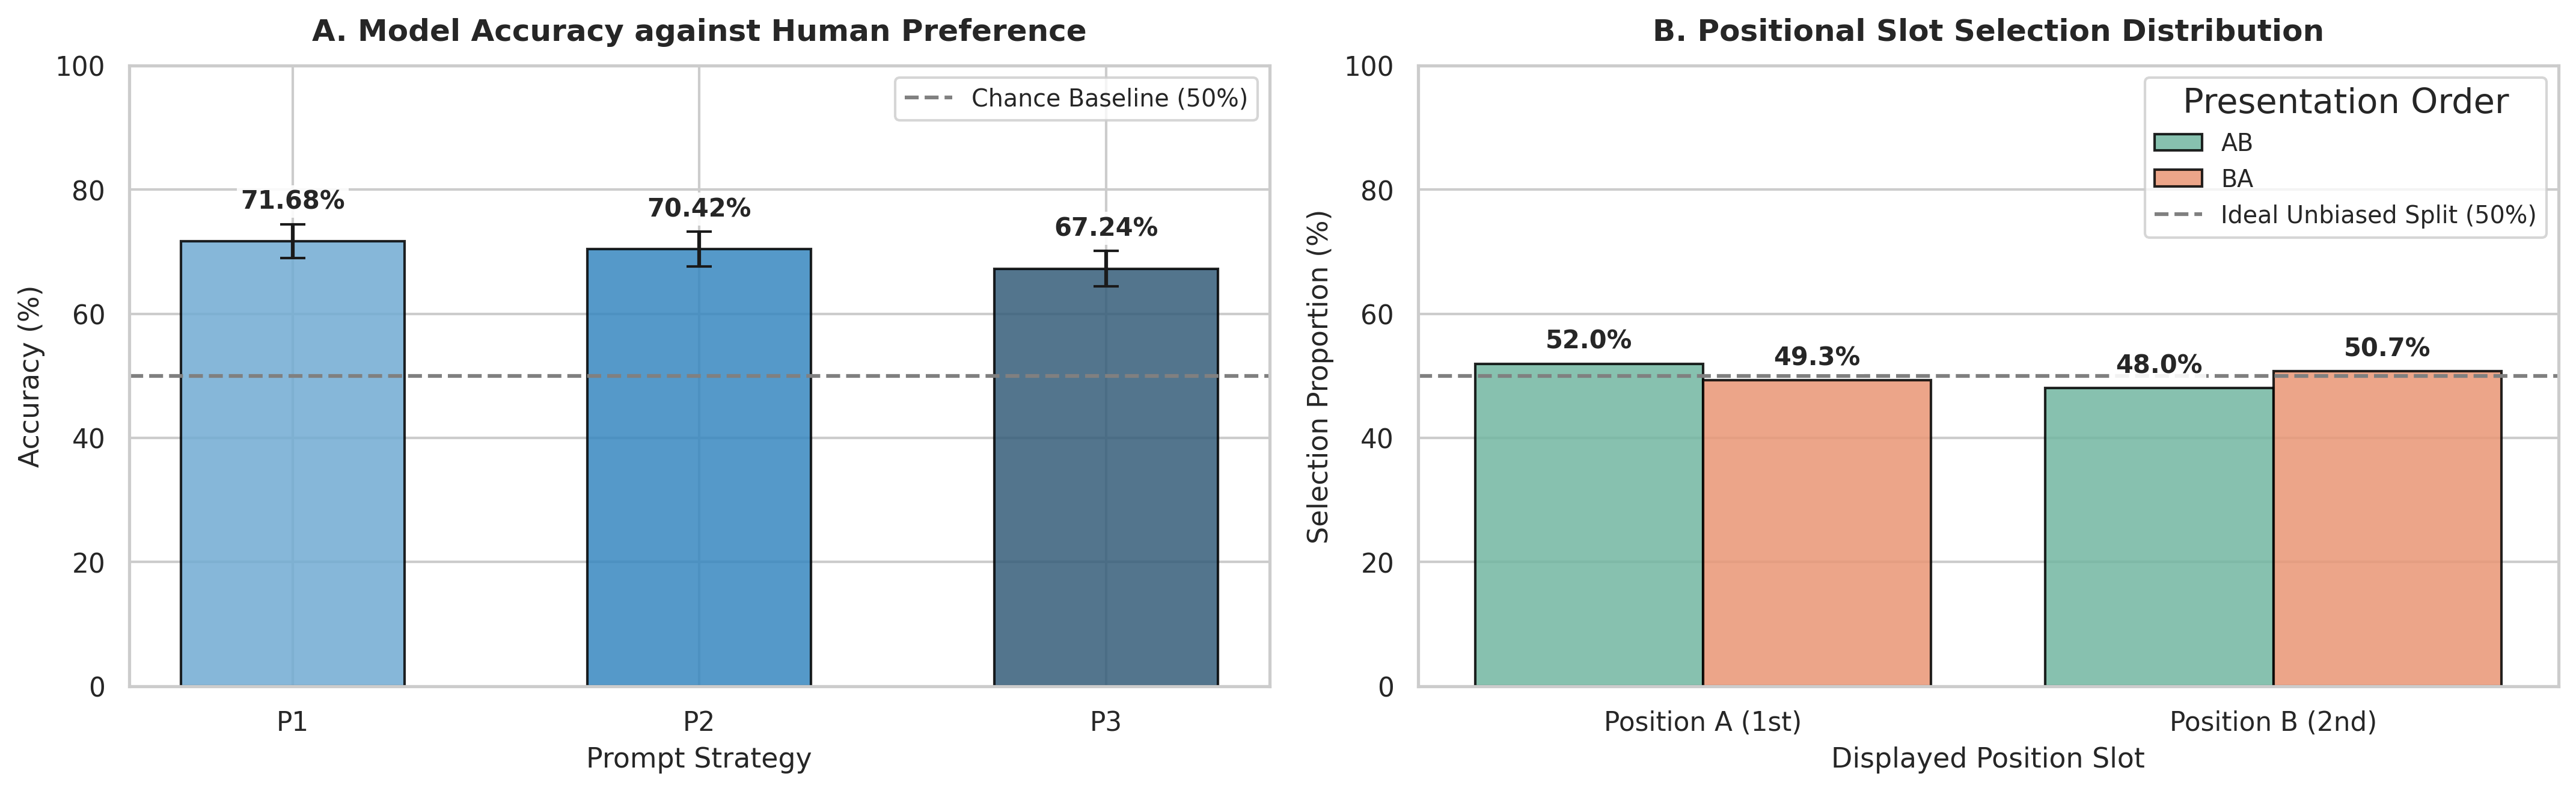

2026-11-28 07:18:15 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_positional_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b
2026-11-28 07:18:15 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_positional_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b
2026-11-28 07:18:16 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_cohen_kappa | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b


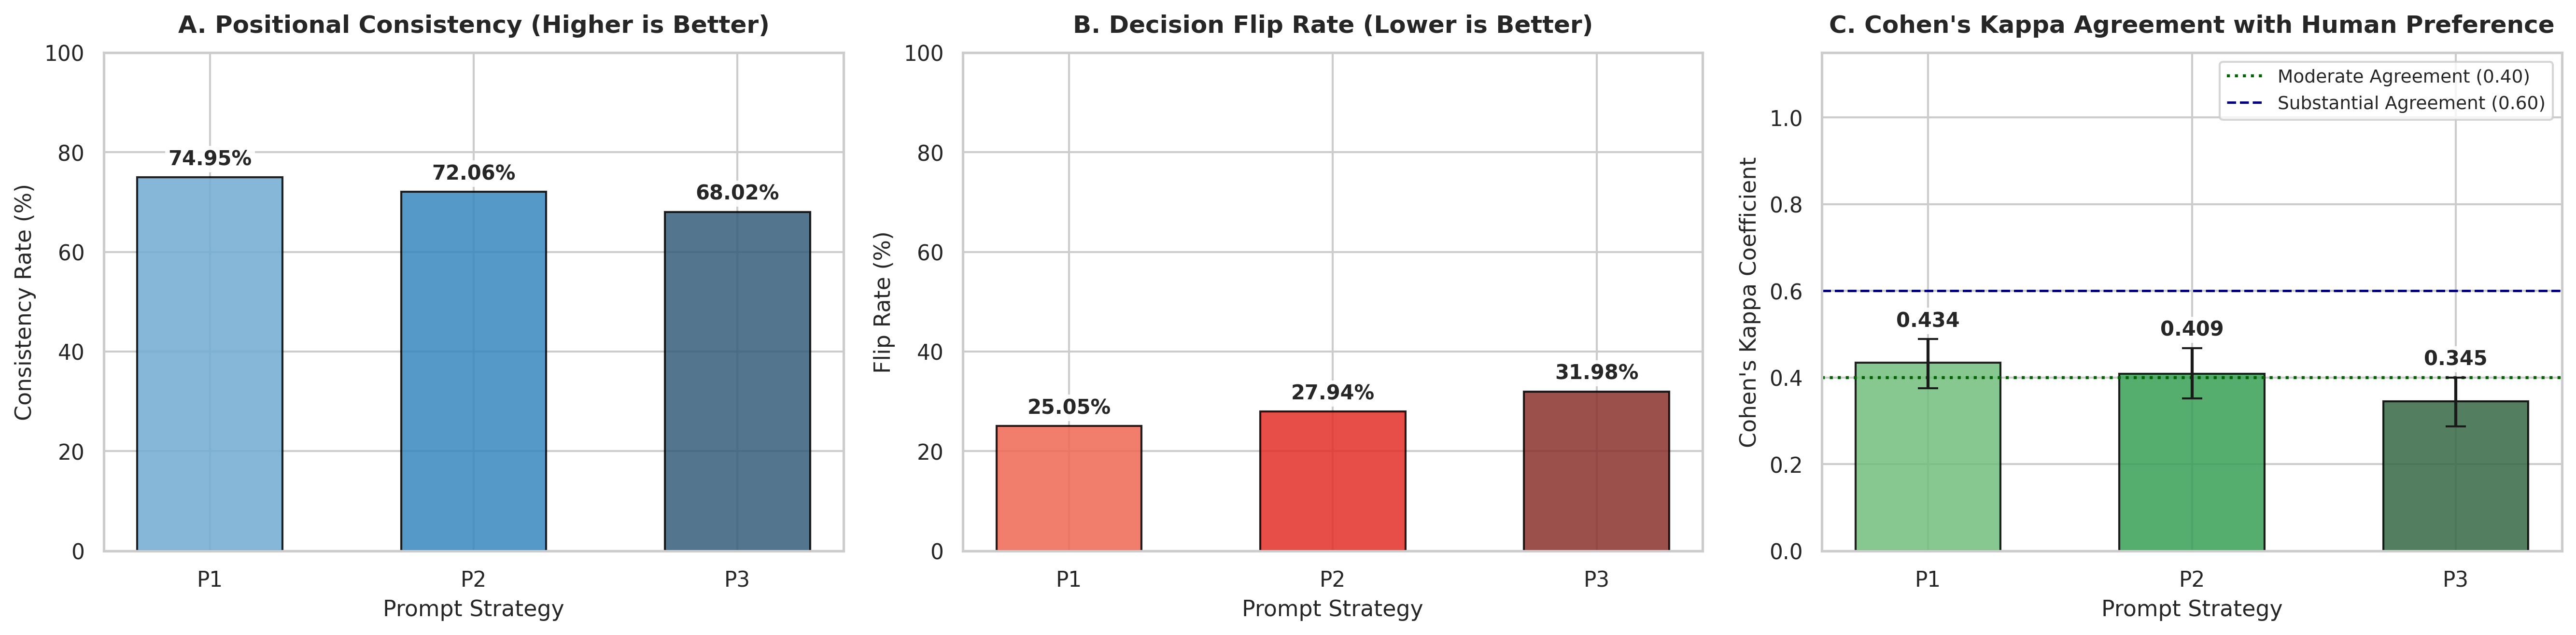

2026-11-28 07:18:16 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_parsing_success_ratio | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b
2026-11-28 07:18:17 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_domain_accuracy | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b


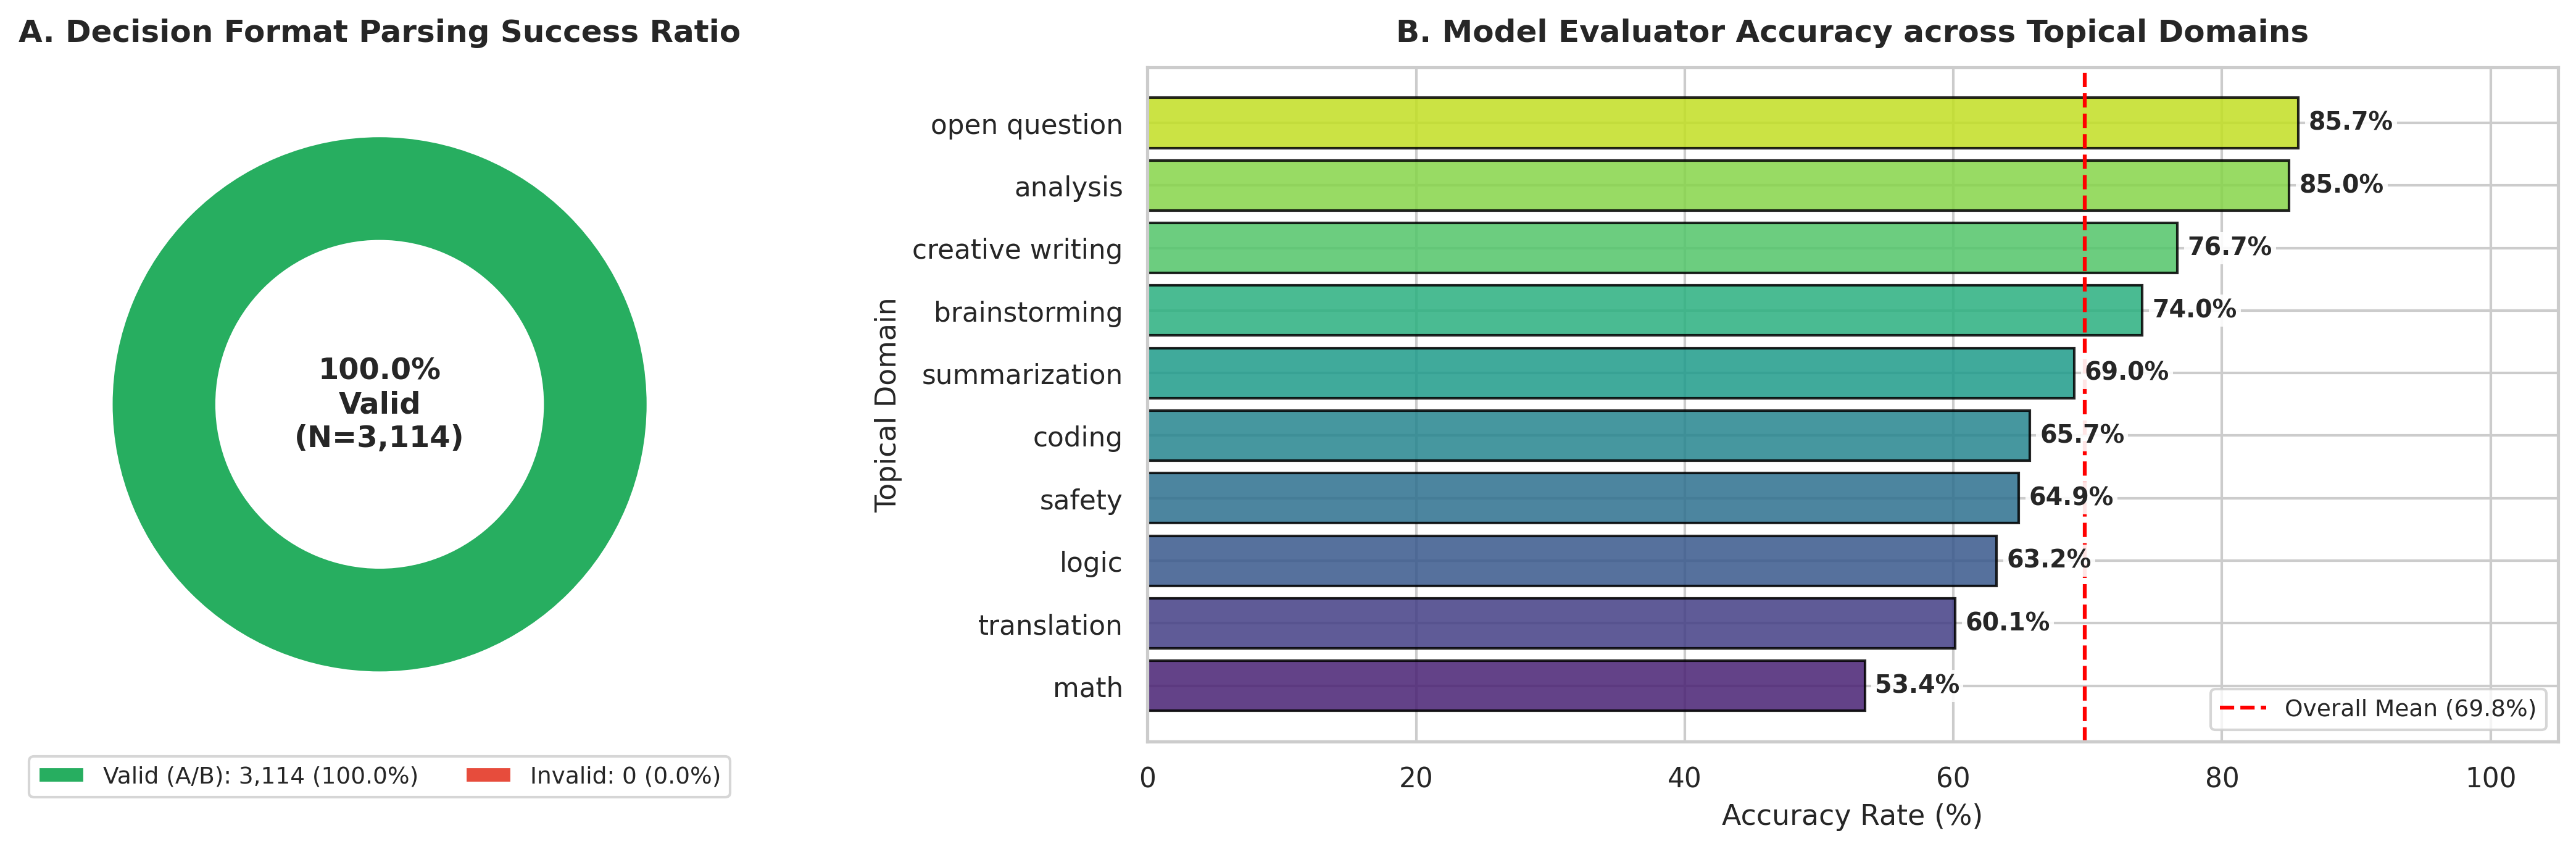

2026-11-28 07:18:18 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_positional_heatmap_p1 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b
2026-11-28 07:18:18 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_positional_heatmap_p2 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b
2026-11-28 07:18:18 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_positional_heatmap_p3 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b


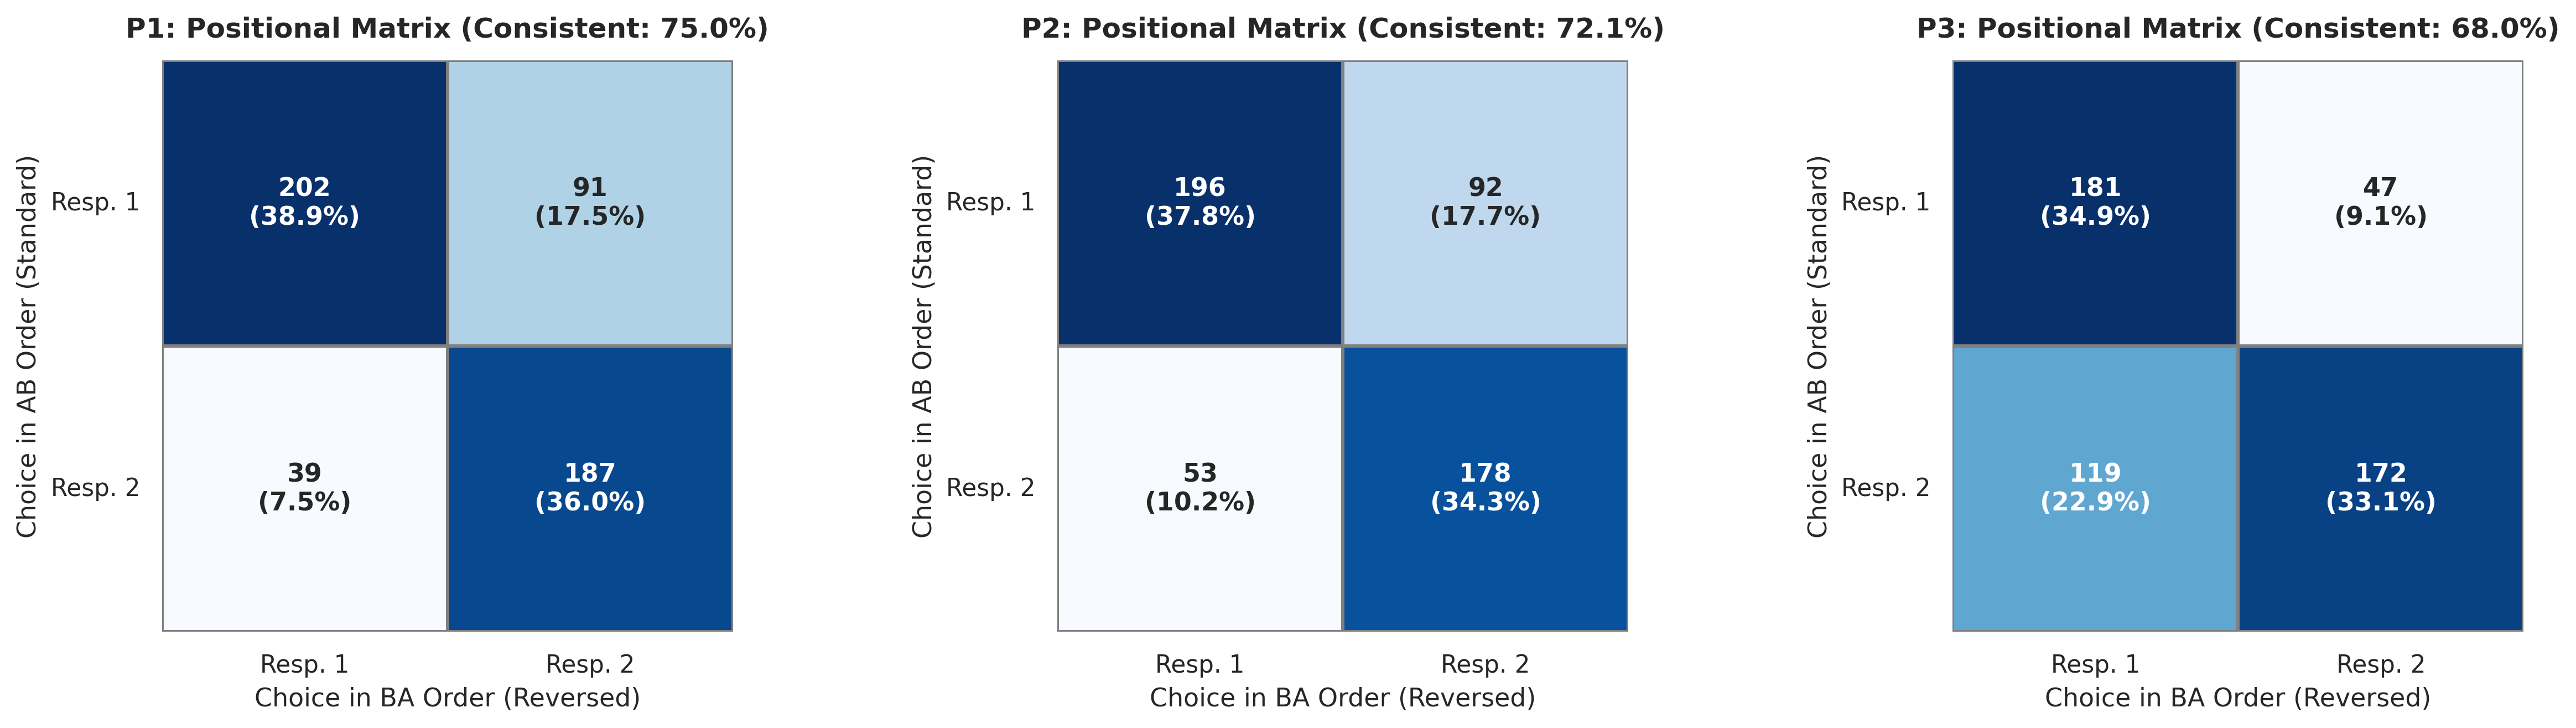

2026-11-28 07:18:19 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_prompt_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b
2026-11-28 07:18:20 | INFO     | llm_exp.mistral_small_3_1_24b | fig_saved | name=plot_prompt_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/mistral_small_3_1_24b


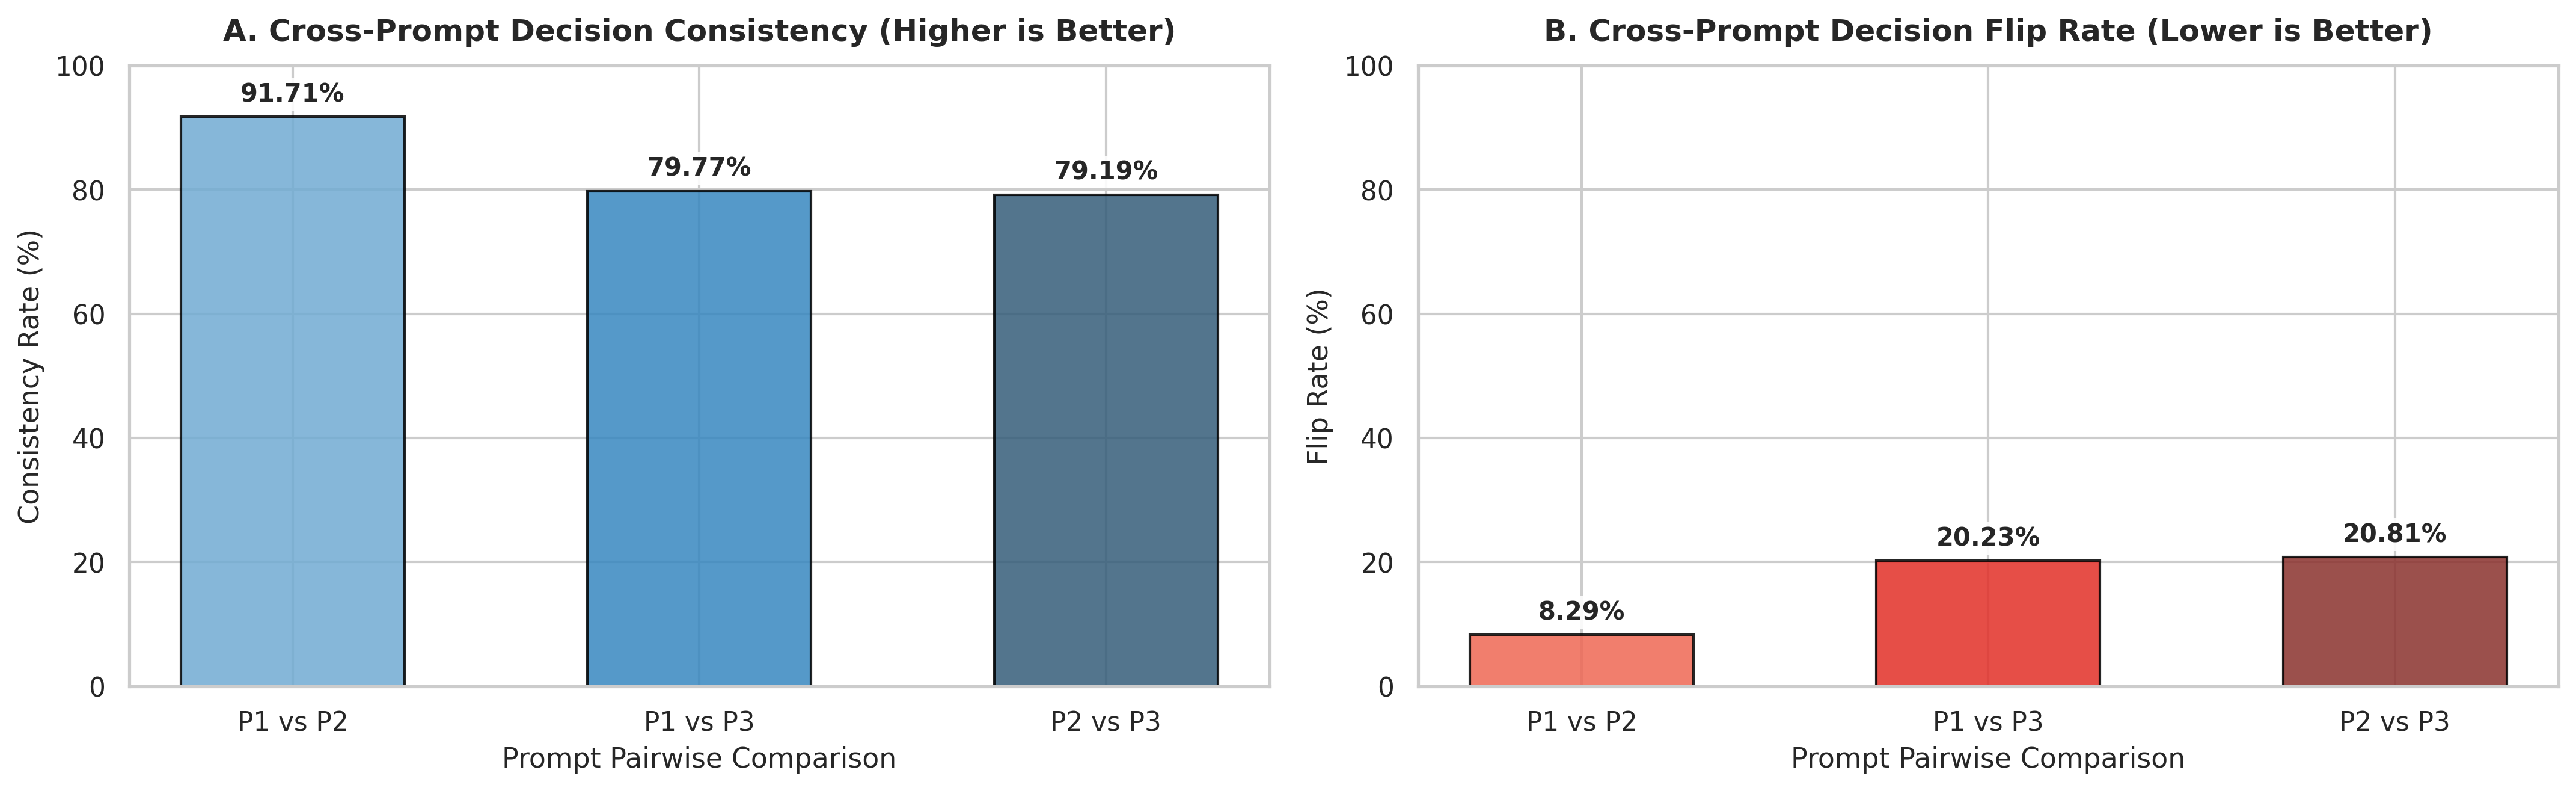

2026-11-28 07:18:20 | INFO     | llm_exp.mistral_small_3_1_24b | stage_done | model=mistral_small_3_1_24b | stage=all


0

In [10]:
execute_model_pipeline("mistral_small_3_1_24b", **PIPELINE_OPTIONS)

### **4.5 GLM-4 32B 0414**

GLM-4 32B 0414 berfungsi sebagai pembanding kelas 32B pada loader `causal_lm` yang memerlukan opsi `trust_remote_code`.

2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | drive_mounted | mount=/content/drive
2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | hf_auth_ok
2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | workspace_ready | root=/content/drive/MyDrive/LLMReliabilityEXP | cache=/content/models
2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | log_init | run_id=glm_4_32b_all_20261128_071820 | tz=Asia/Jakarta | path=/content/drive/MyDrive/LLMReliabilityEXP/logs/2026-11-28/glm_4_32b_all_20261128_071820.log
2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | schema_ok | rows=519 | cols=10
2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | dataset_cache_hit | split=eval | rows=519 | path=/content/drive/MyDrive/LLMReliabilityEXP/data/processed/indopref_eval_stratified.parquet
2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | resume_status | model=glm_4_32b | total=3114 | done=3114 | pending=0
2026-11-28 07:18:20 | INFO     | llm_exp.glm_4_32b | infer_skip | model=glm_4_32b | reason=

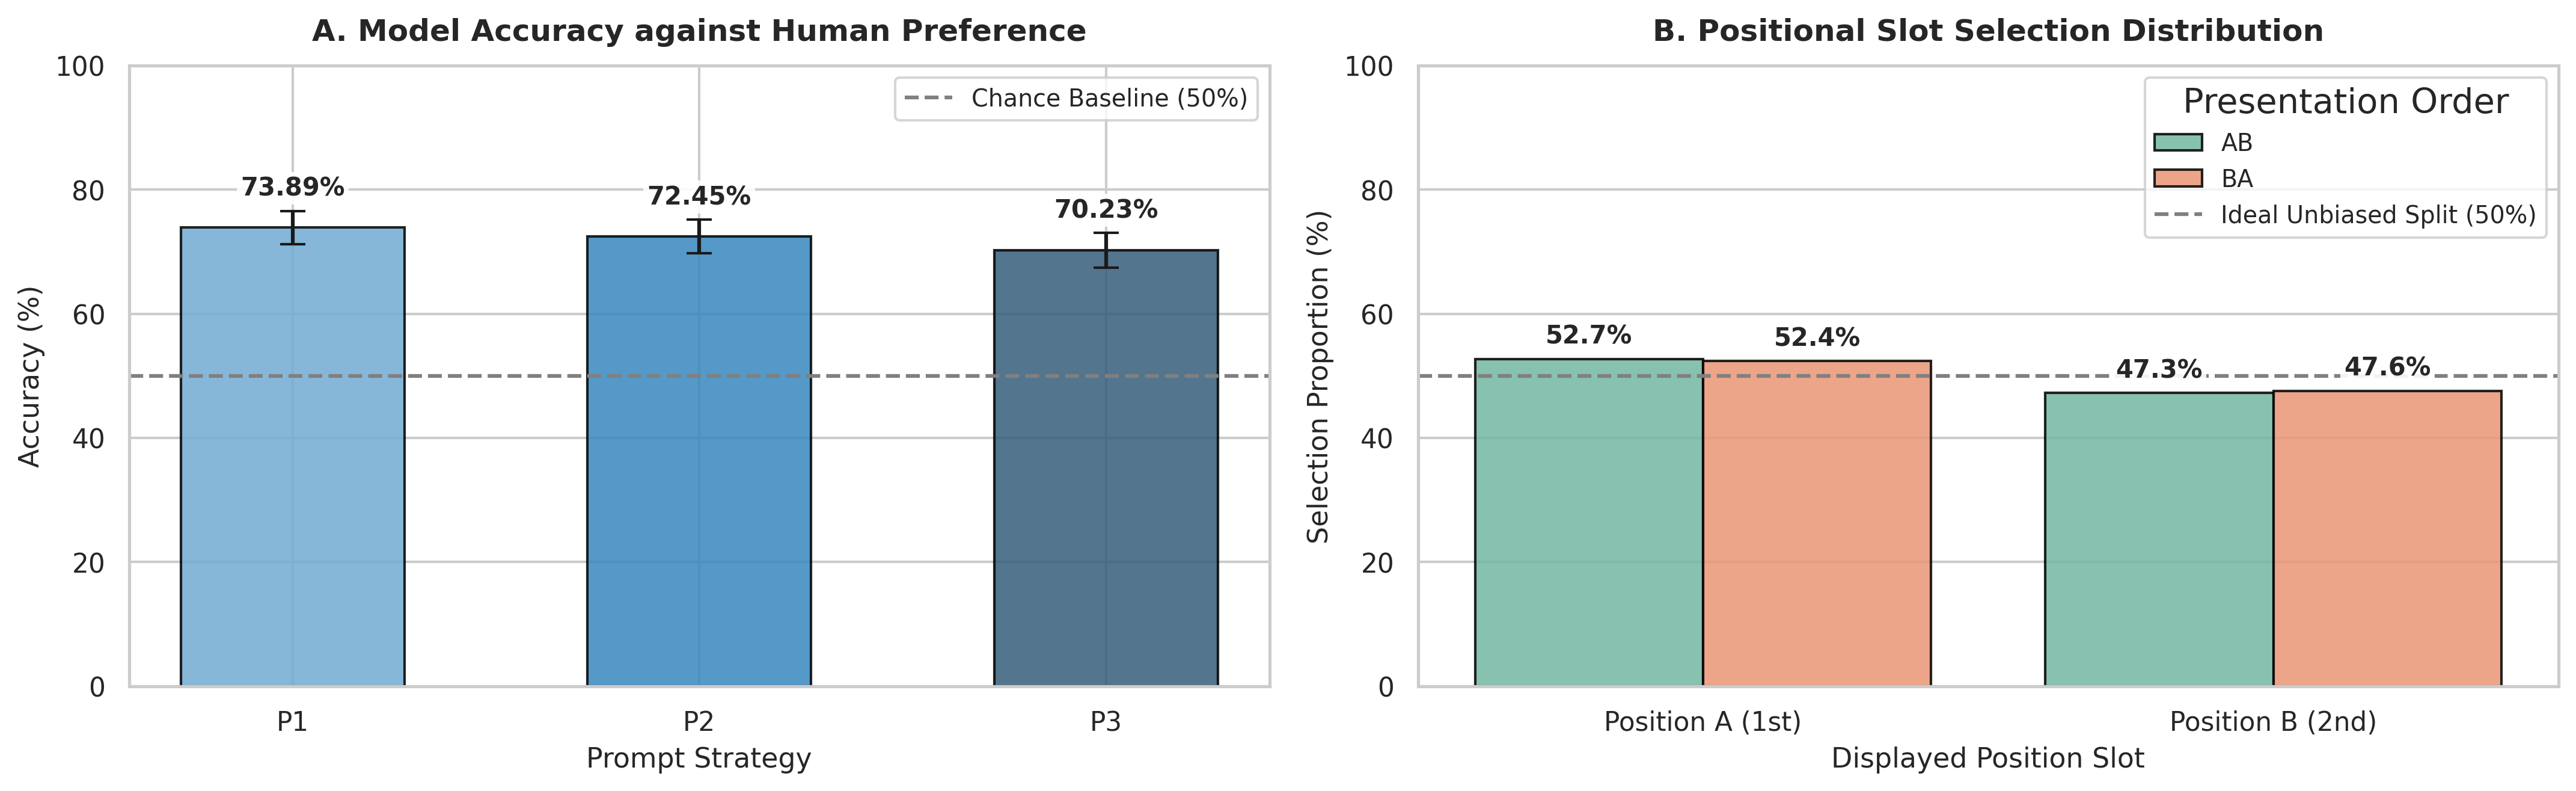

2026-11-28 07:18:24 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_positional_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b
2026-11-28 07:18:24 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_positional_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b
2026-11-28 07:18:25 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_cohen_kappa | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b


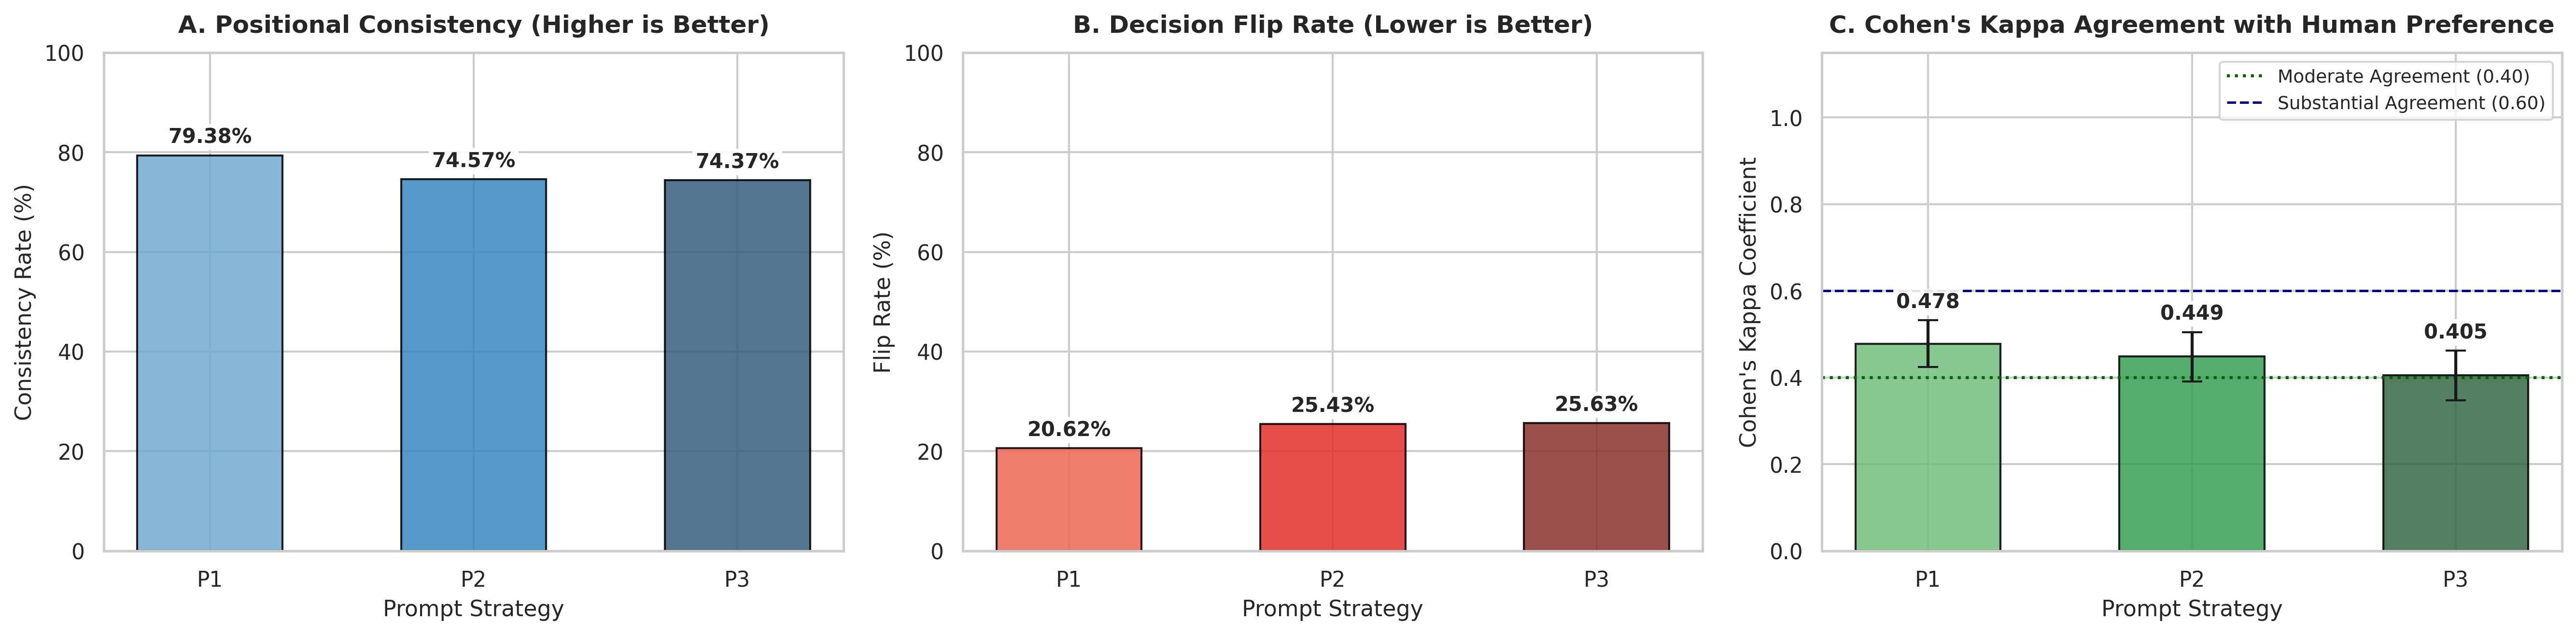

2026-11-28 07:18:26 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_parsing_success_ratio | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b
2026-11-28 07:18:26 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_domain_accuracy | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b


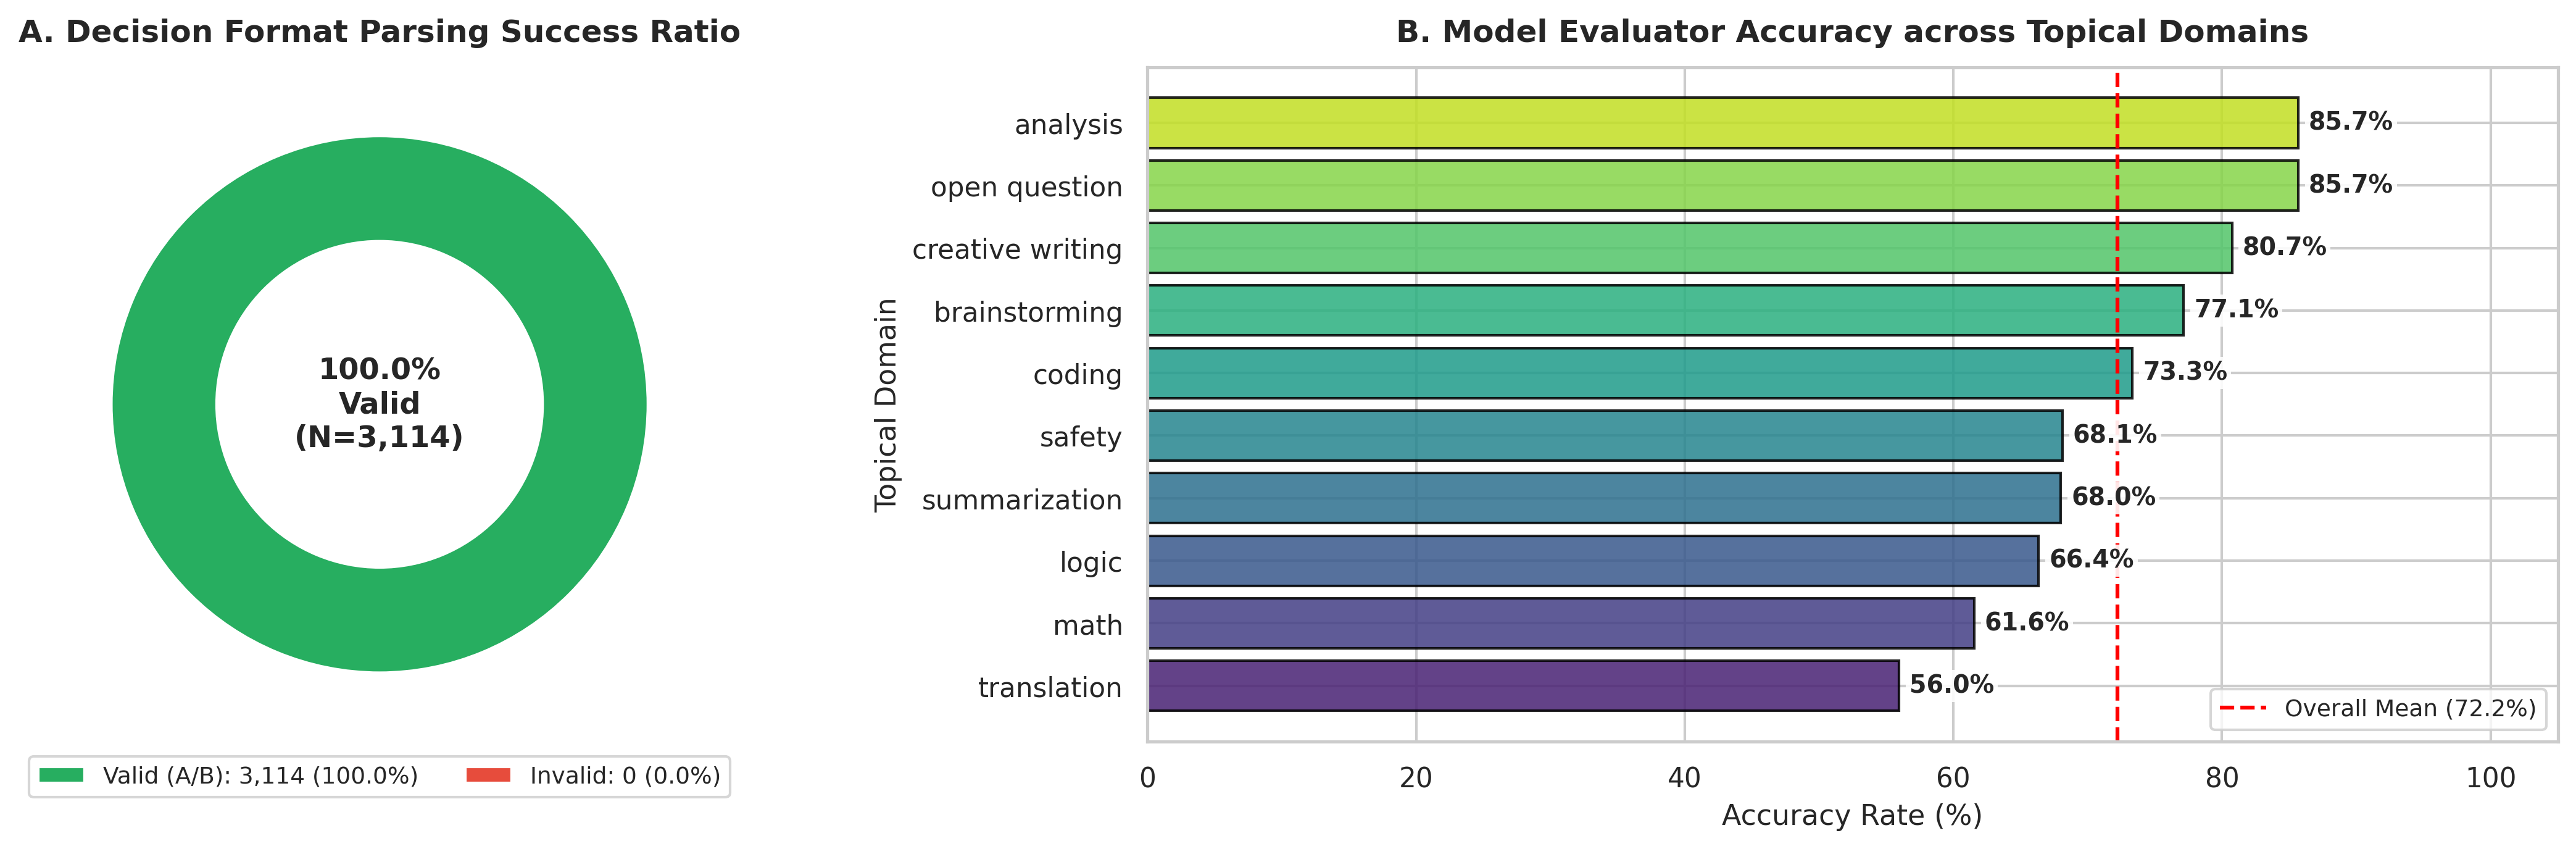

2026-11-28 07:18:27 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_positional_heatmap_p1 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b
2026-11-28 07:18:27 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_positional_heatmap_p2 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b
2026-11-28 07:18:28 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_positional_heatmap_p3 | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b


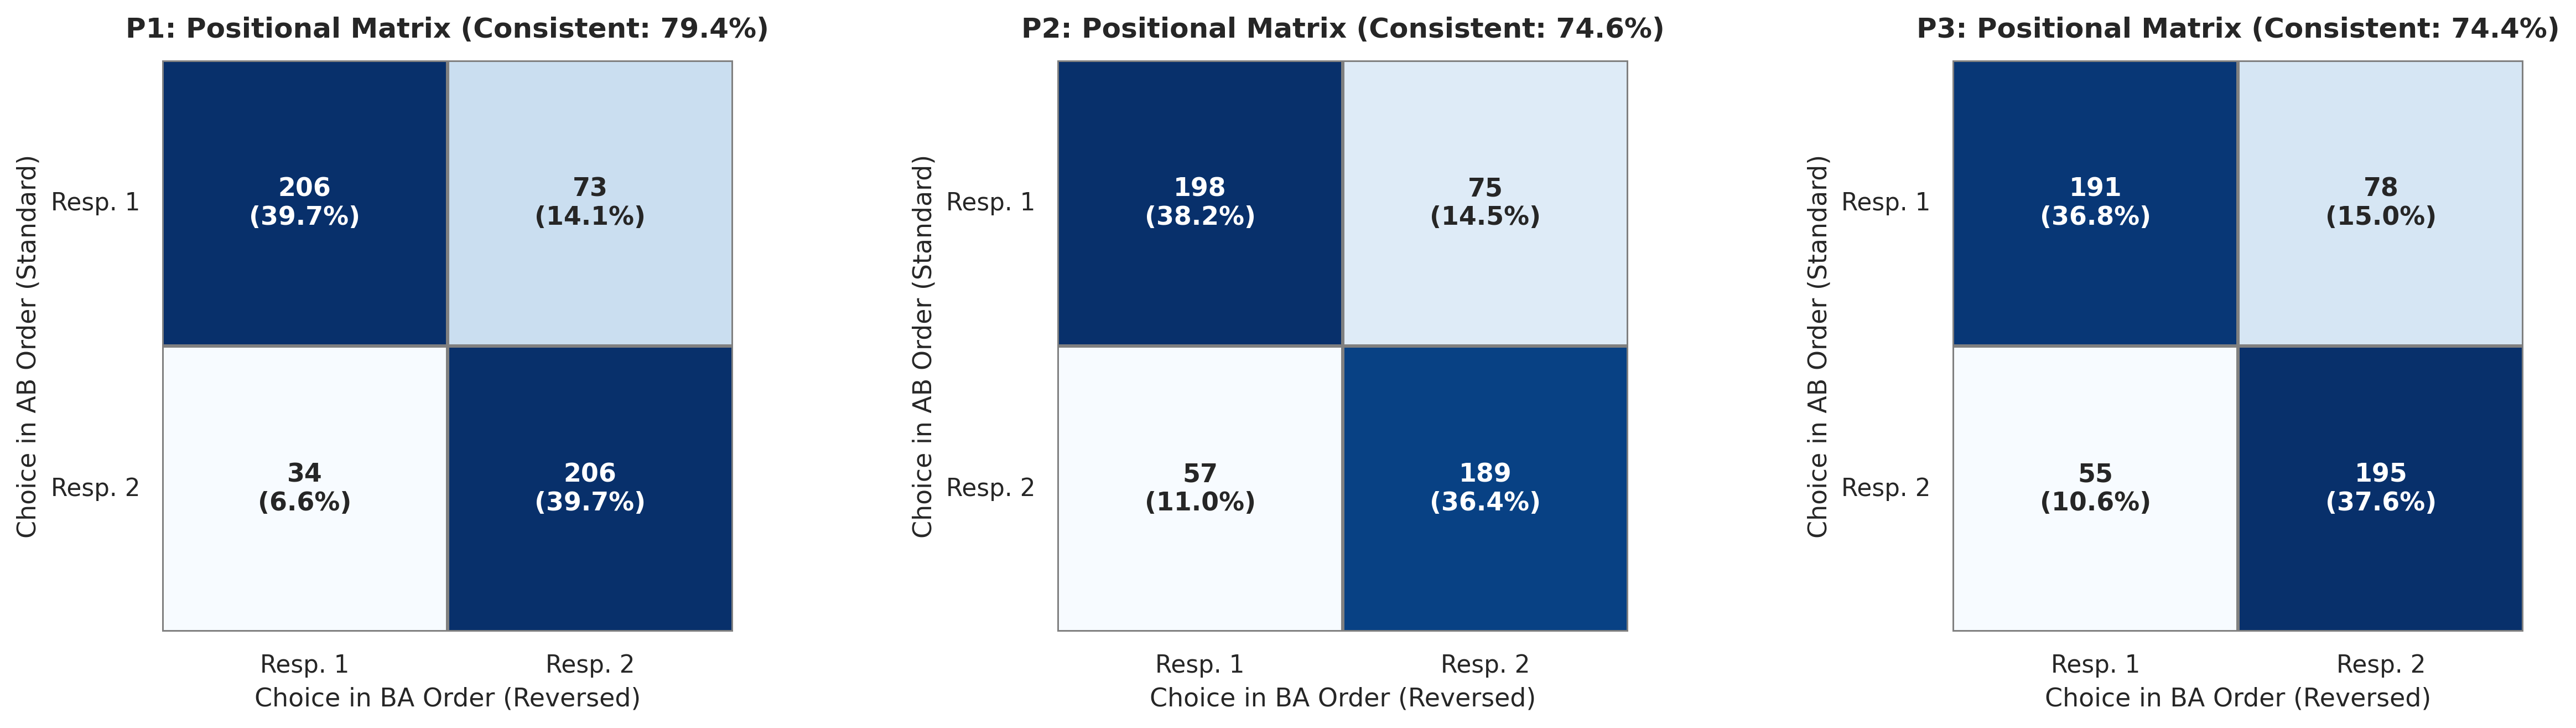

2026-11-28 07:18:29 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_prompt_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b
2026-11-28 07:18:29 | INFO     | llm_exp.glm_4_32b | fig_saved | name=plot_prompt_flip_rate | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/glm_4_32b


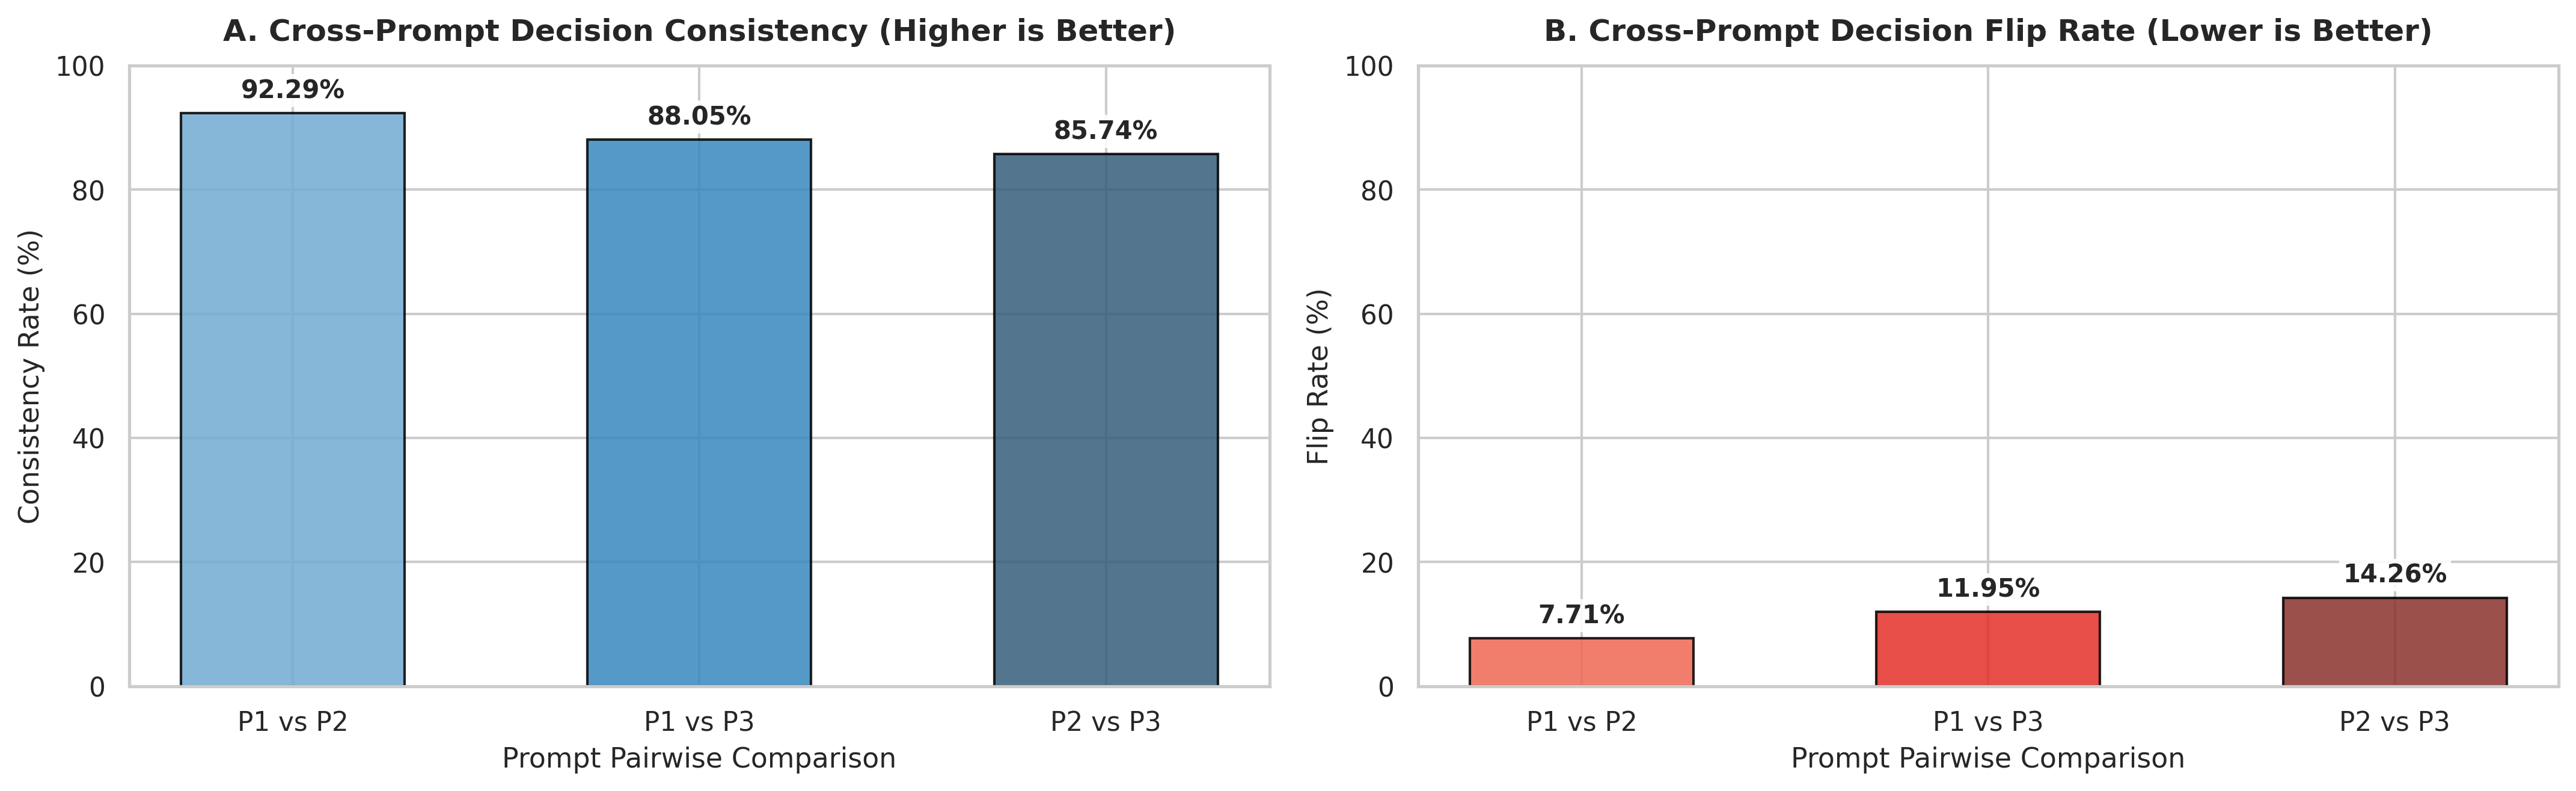

2026-11-28 07:18:29 | INFO     | llm_exp.glm_4_32b | stage_done | model=glm_4_32b | stage=all


0

In [11]:
execute_model_pipeline("glm_4_32b", **PIPELINE_OPTIONS)

## **5. Komparasi Hasil**

Metrik dari seluruh model yang telah selesai dievaluasi digabungkan pada bagian ini. Grafik perbandingan disimpan ke `results/comparison/`, lalu tabel ringkasan dan akurasi per domain ditampilkan di bawahnya.

2026-11-28 07:18:29 | INFO     | llm_exp.comparison | drive_mounted | mount=/content/drive
2026-11-28 07:18:29 | INFO     | llm_exp.comparison | workspace_ready | root=/content/drive/MyDrive/LLMReliabilityEXP | cache=/content/models
2026-11-28 07:18:29 | INFO     | llm_exp.comparison | log_init | run_id=comparison_20261128_071829 | tz=Asia/Jakarta | path=/content/drive/MyDrive/LLMReliabilityEXP/logs/2026-11-28/comparison_20261128_071829.log
2026-11-28 07:18:29 | INFO     | llm_exp.comparison | eval_parsed | total=3114 | invalid=0 | invalid_pct=0.00
2026-11-28 07:18:29 | INFO     | llm_exp.comparison | pos_metrics | model=qwen3_32b | cons_pct=67.05 | flip_pct=32.95 | slot_a_pct=65.77 | mcnemar_p=8.59406e-104
2026-11-28 07:18:31 | INFO     | llm_exp.comparison | eval_tables_saved | model=qwen3_32b | path=/content/drive/MyDrive/LLMReliabilityEXP/results/qwen3_32b
2026-11-28 07:18:32 | INFO     | llm_exp.comparison | eval_parsed | total=3114 | invalid=0 | invalid_pct=0.00
2026-11-28 07:18:

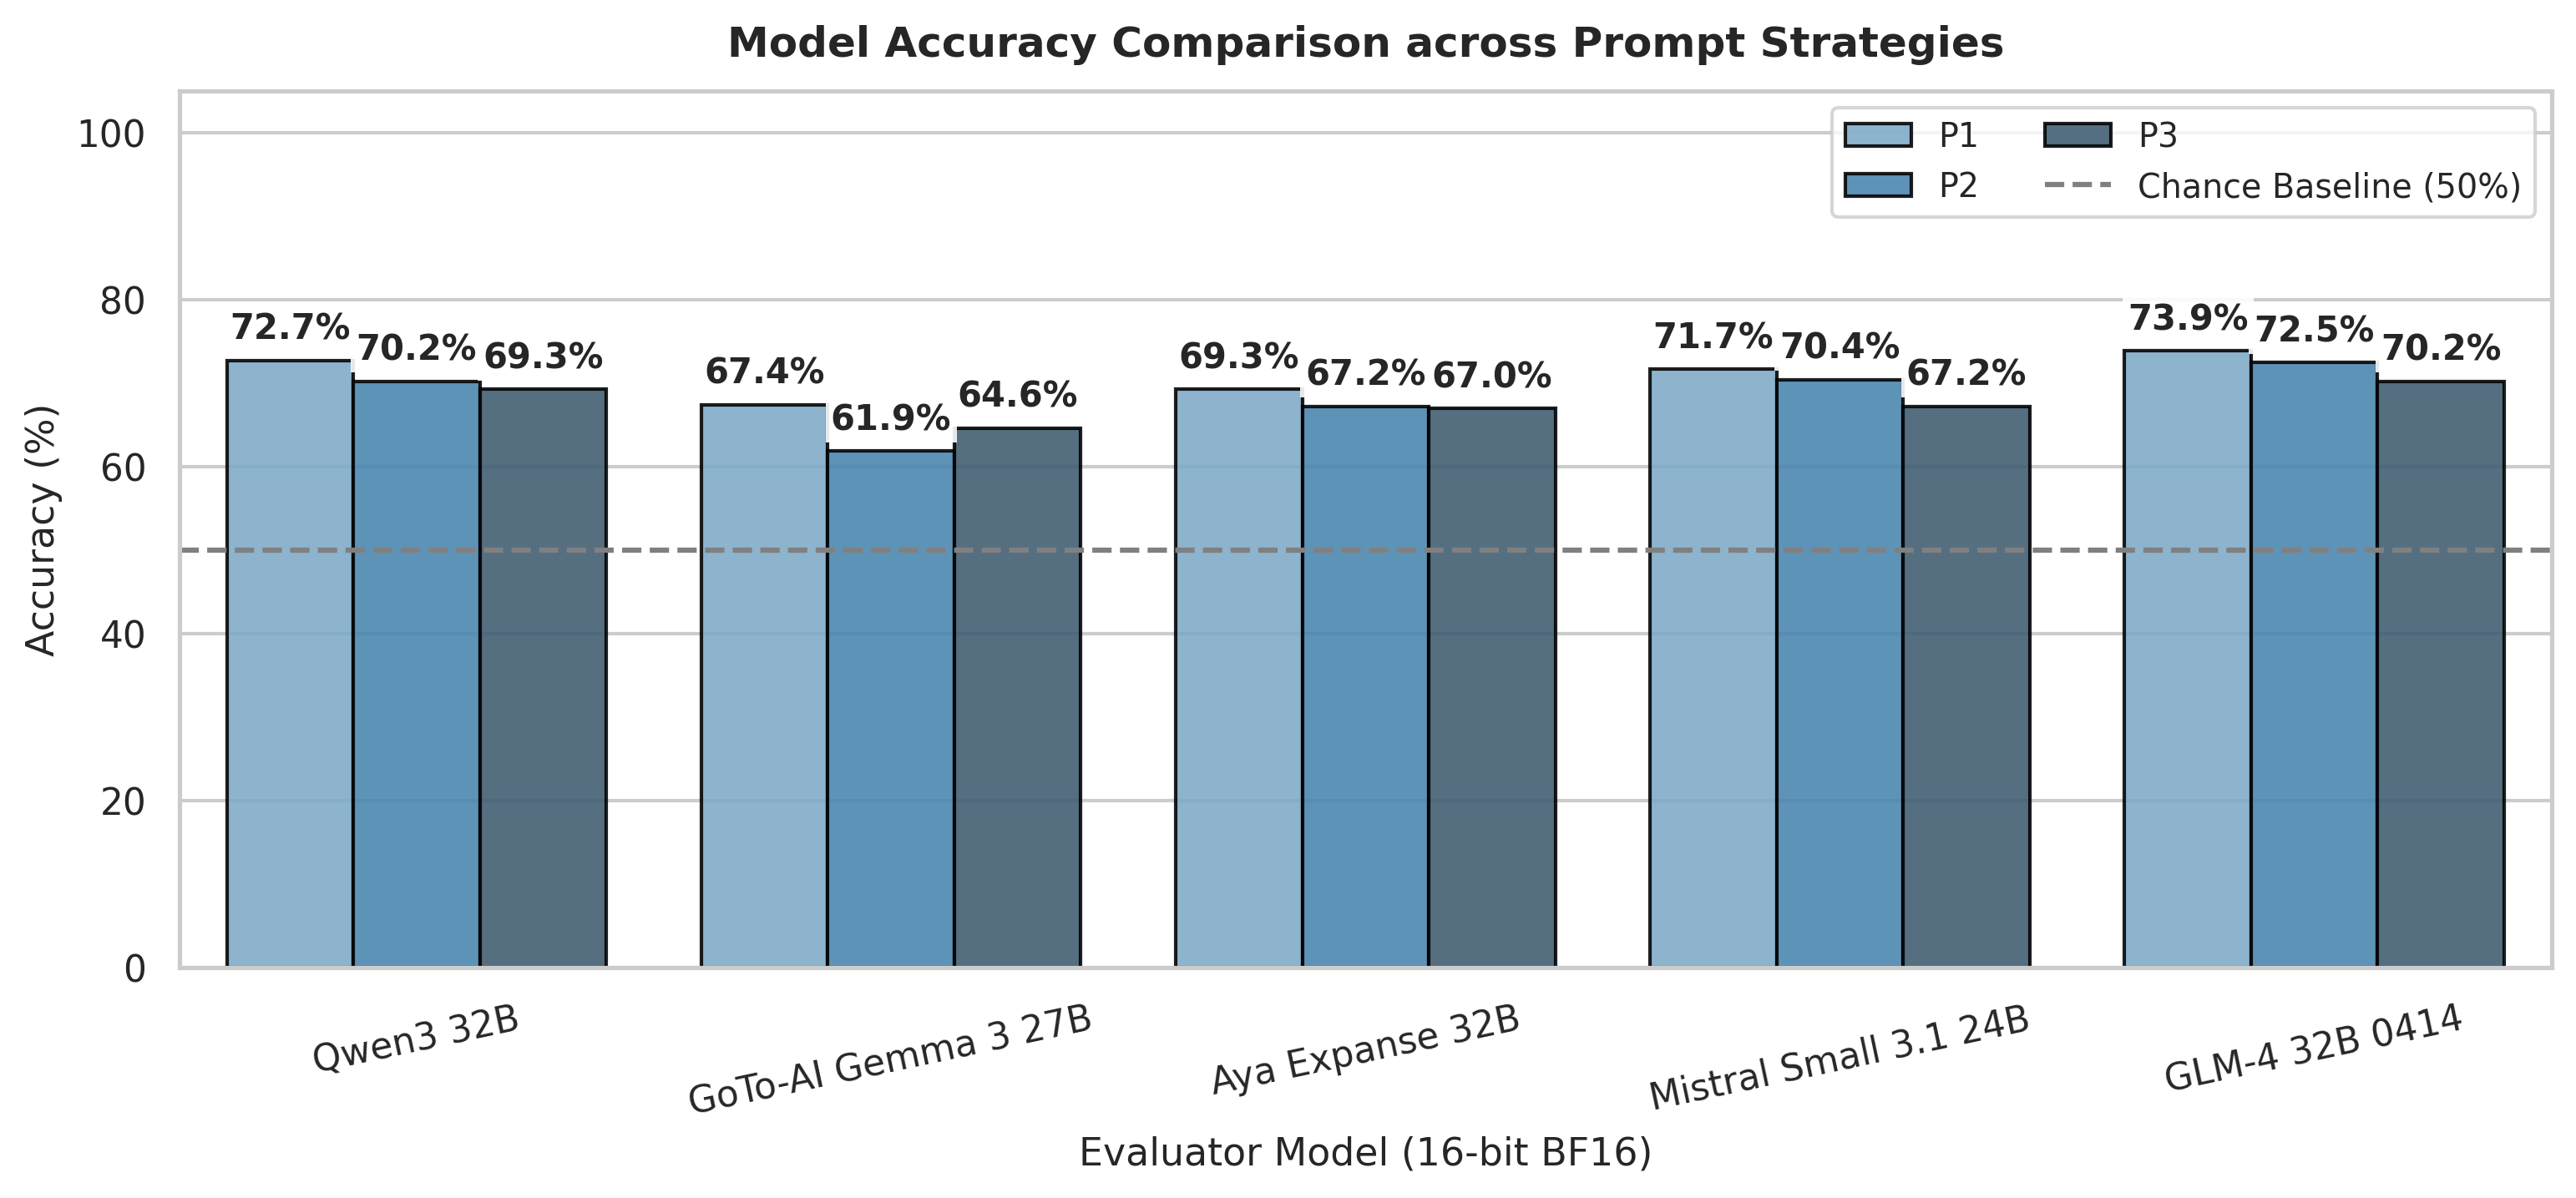

2026-11-28 07:18:41 | INFO     | llm_exp.comparison | fig_saved | name=comparison_positional_consistency | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/comparison
2026-11-28 07:18:42 | INFO     | llm_exp.comparison | fig_saved | name=comparison_cohen_kappa | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/comparison


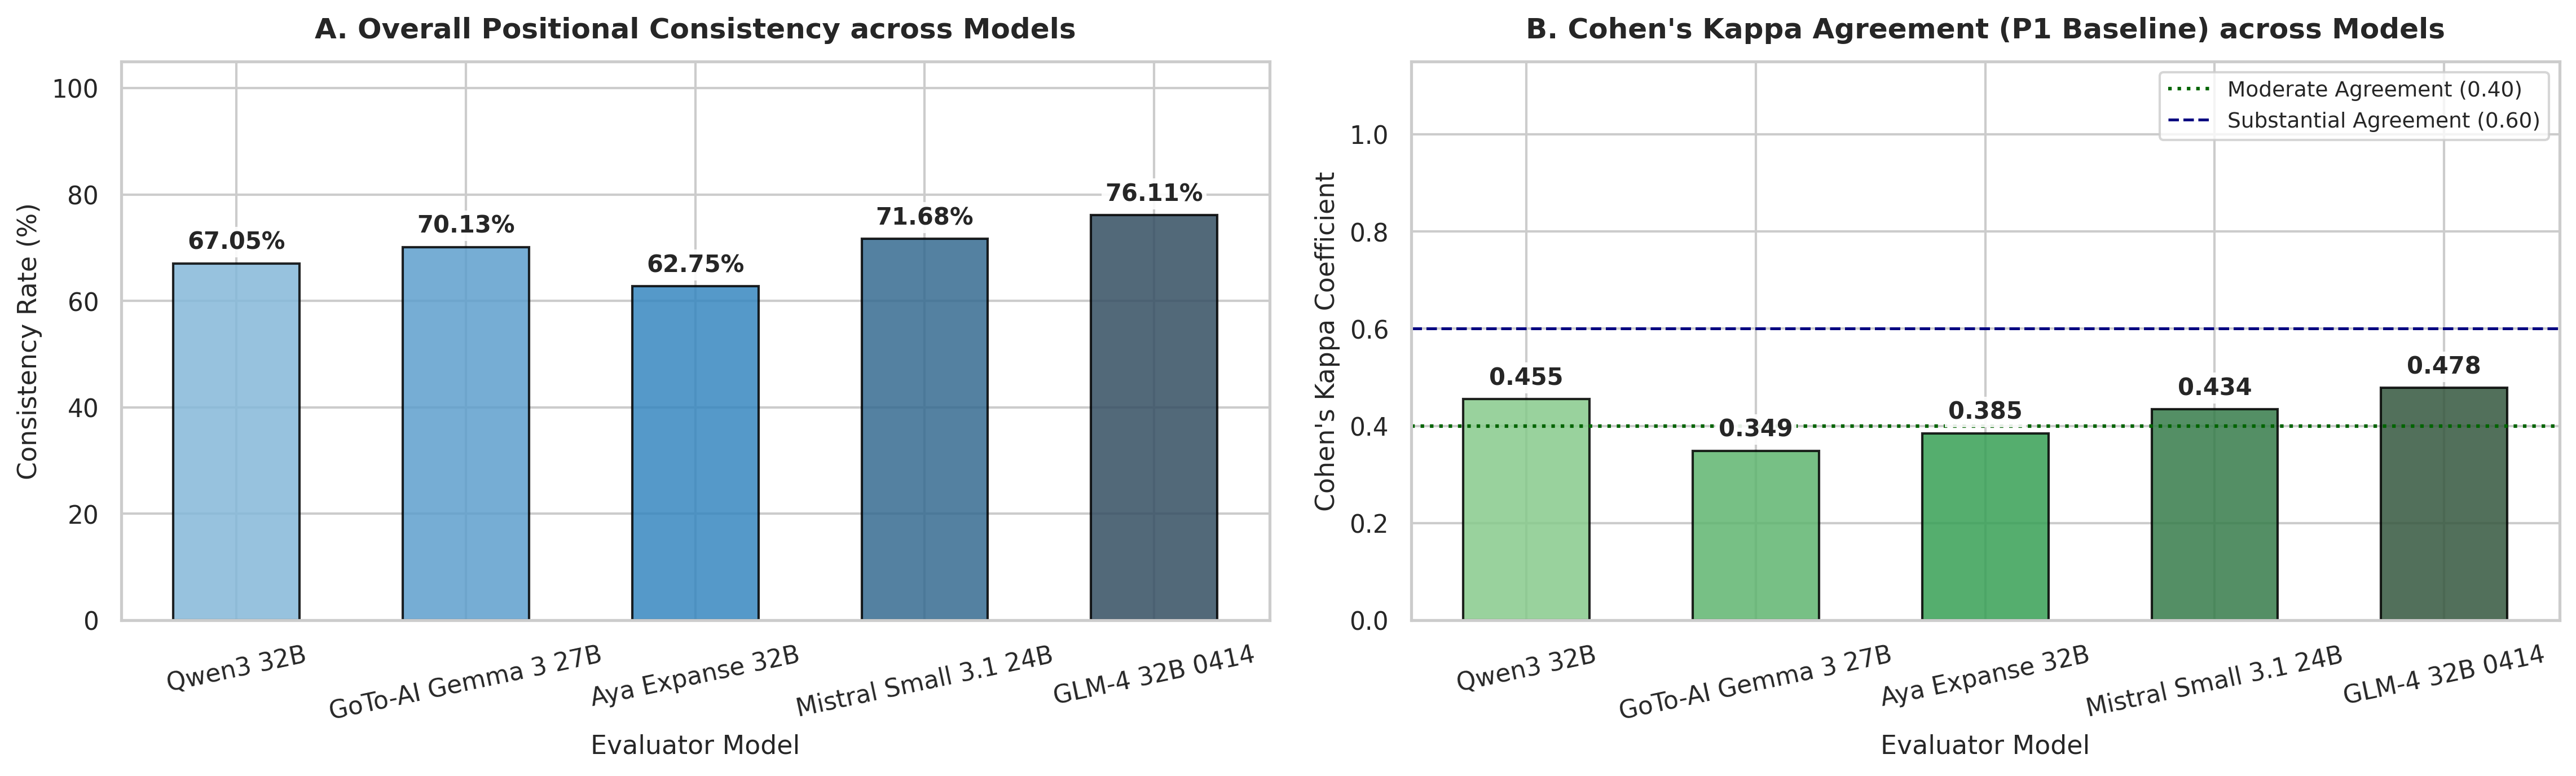

2026-11-28 07:18:43 | INFO     | llm_exp.comparison | fig_saved | name=comparison_3way_prompt_stability | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/comparison


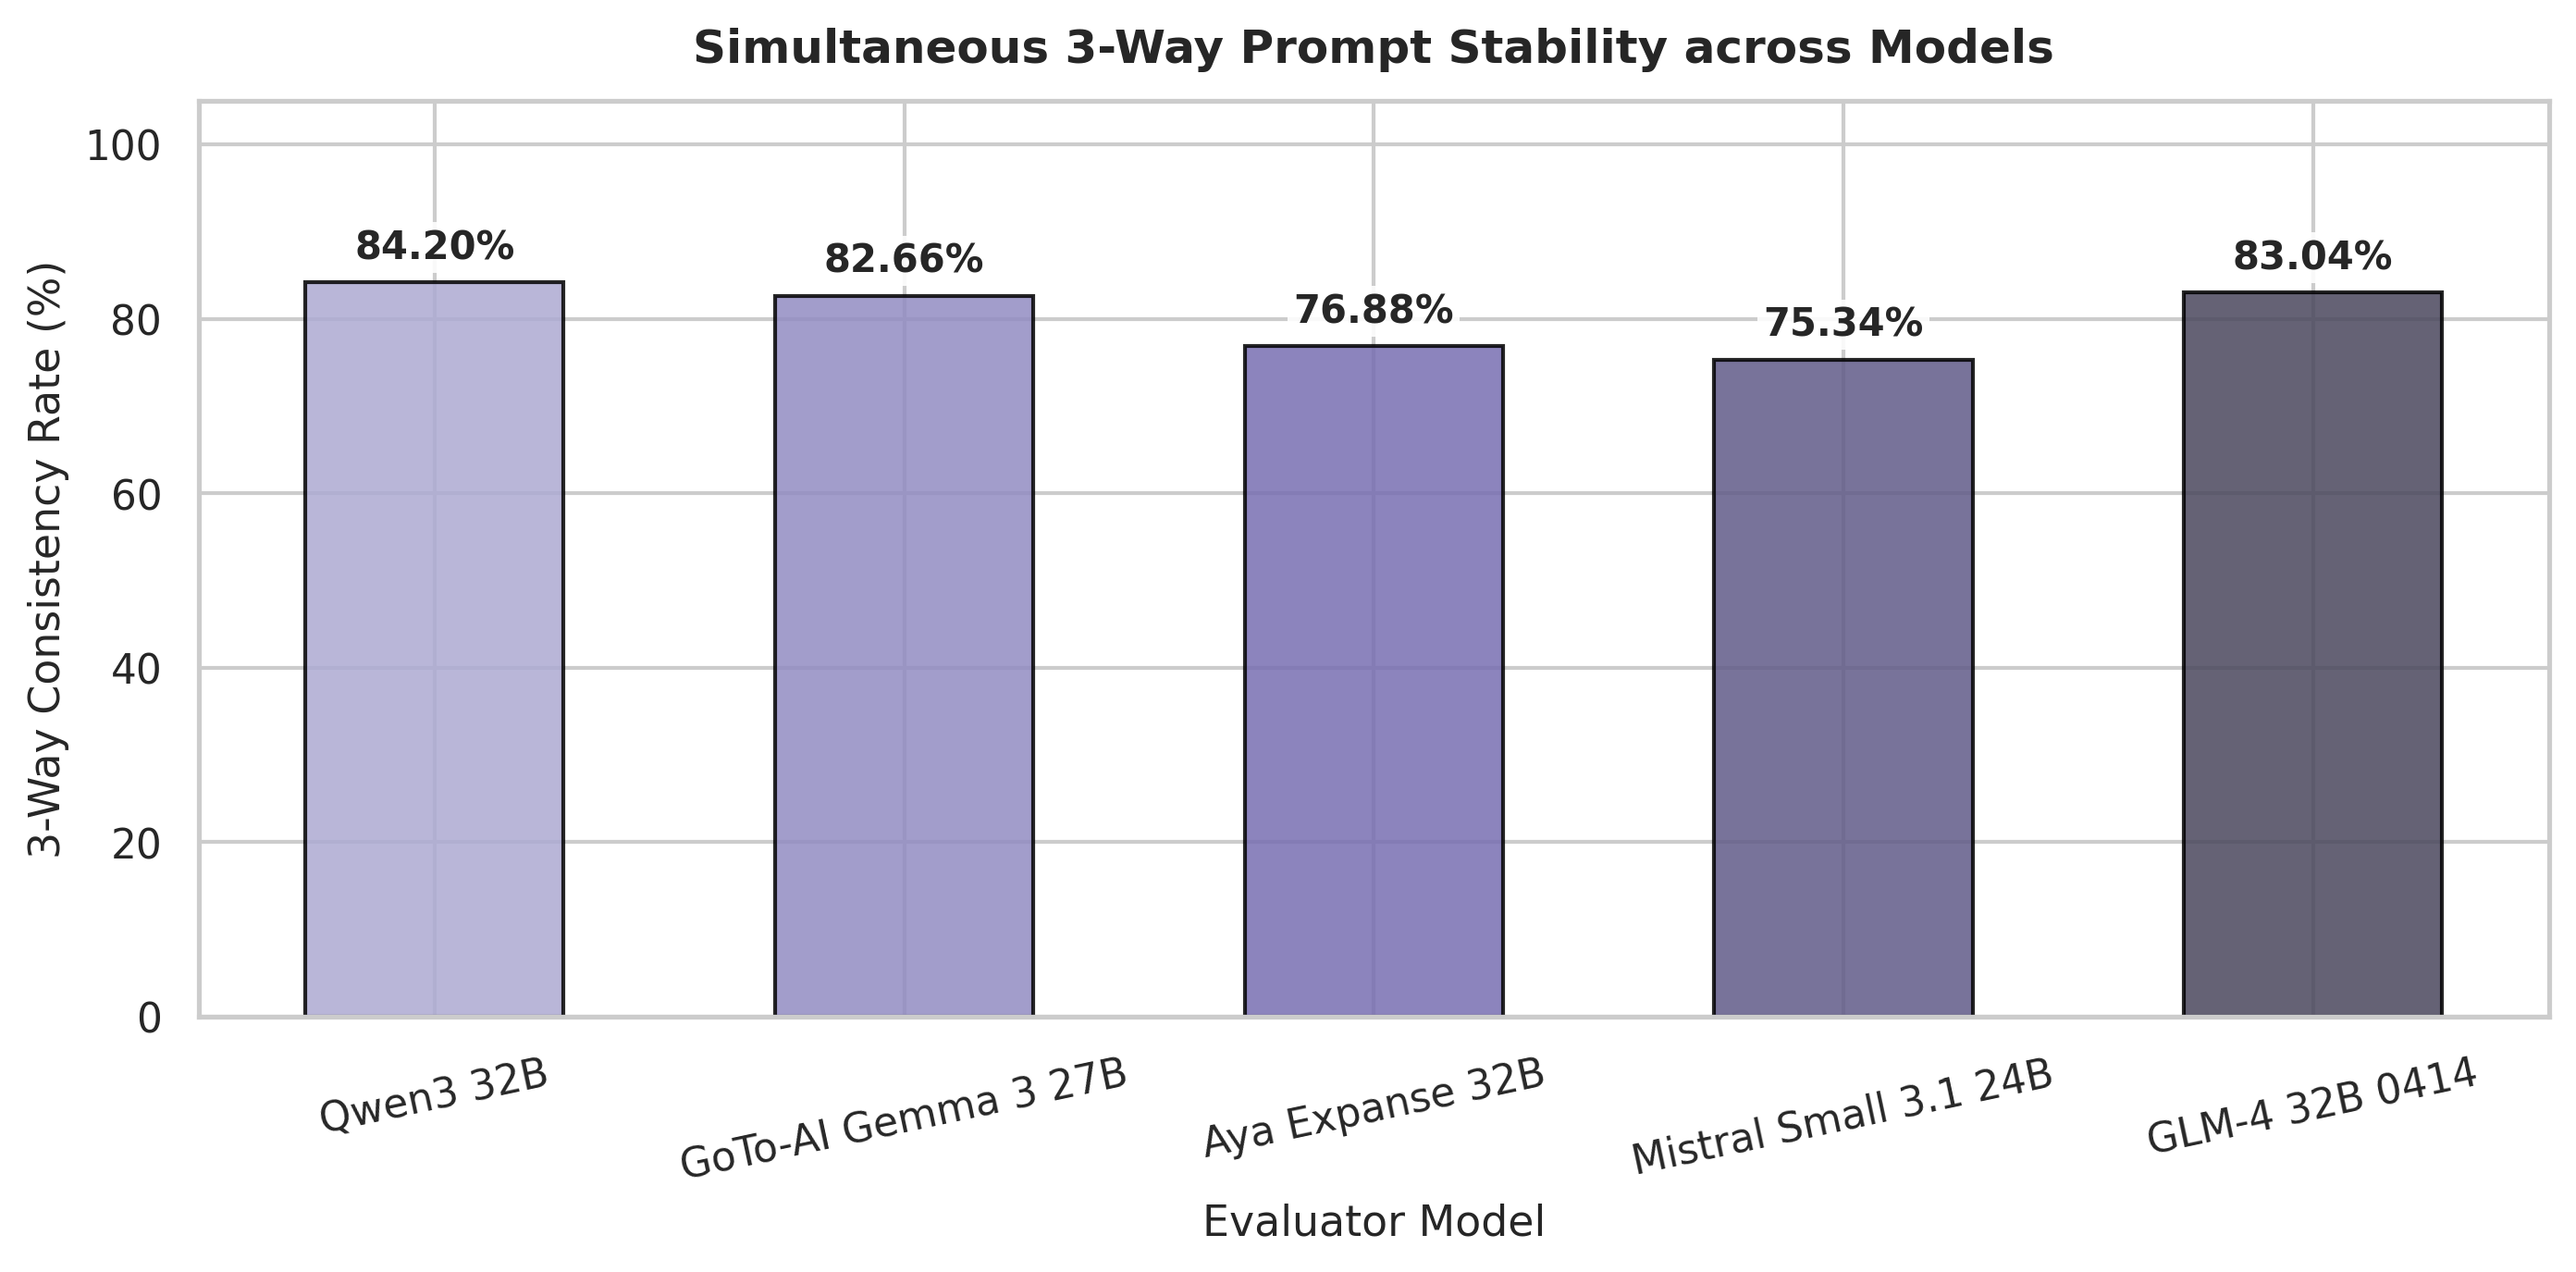

2026-11-28 07:18:44 | INFO     | llm_exp.comparison | fig_saved | name=comparison_domain_accuracy_heatmap | formats=png,svg | path=/content/drive/MyDrive/LLMReliabilityEXP/results/comparison


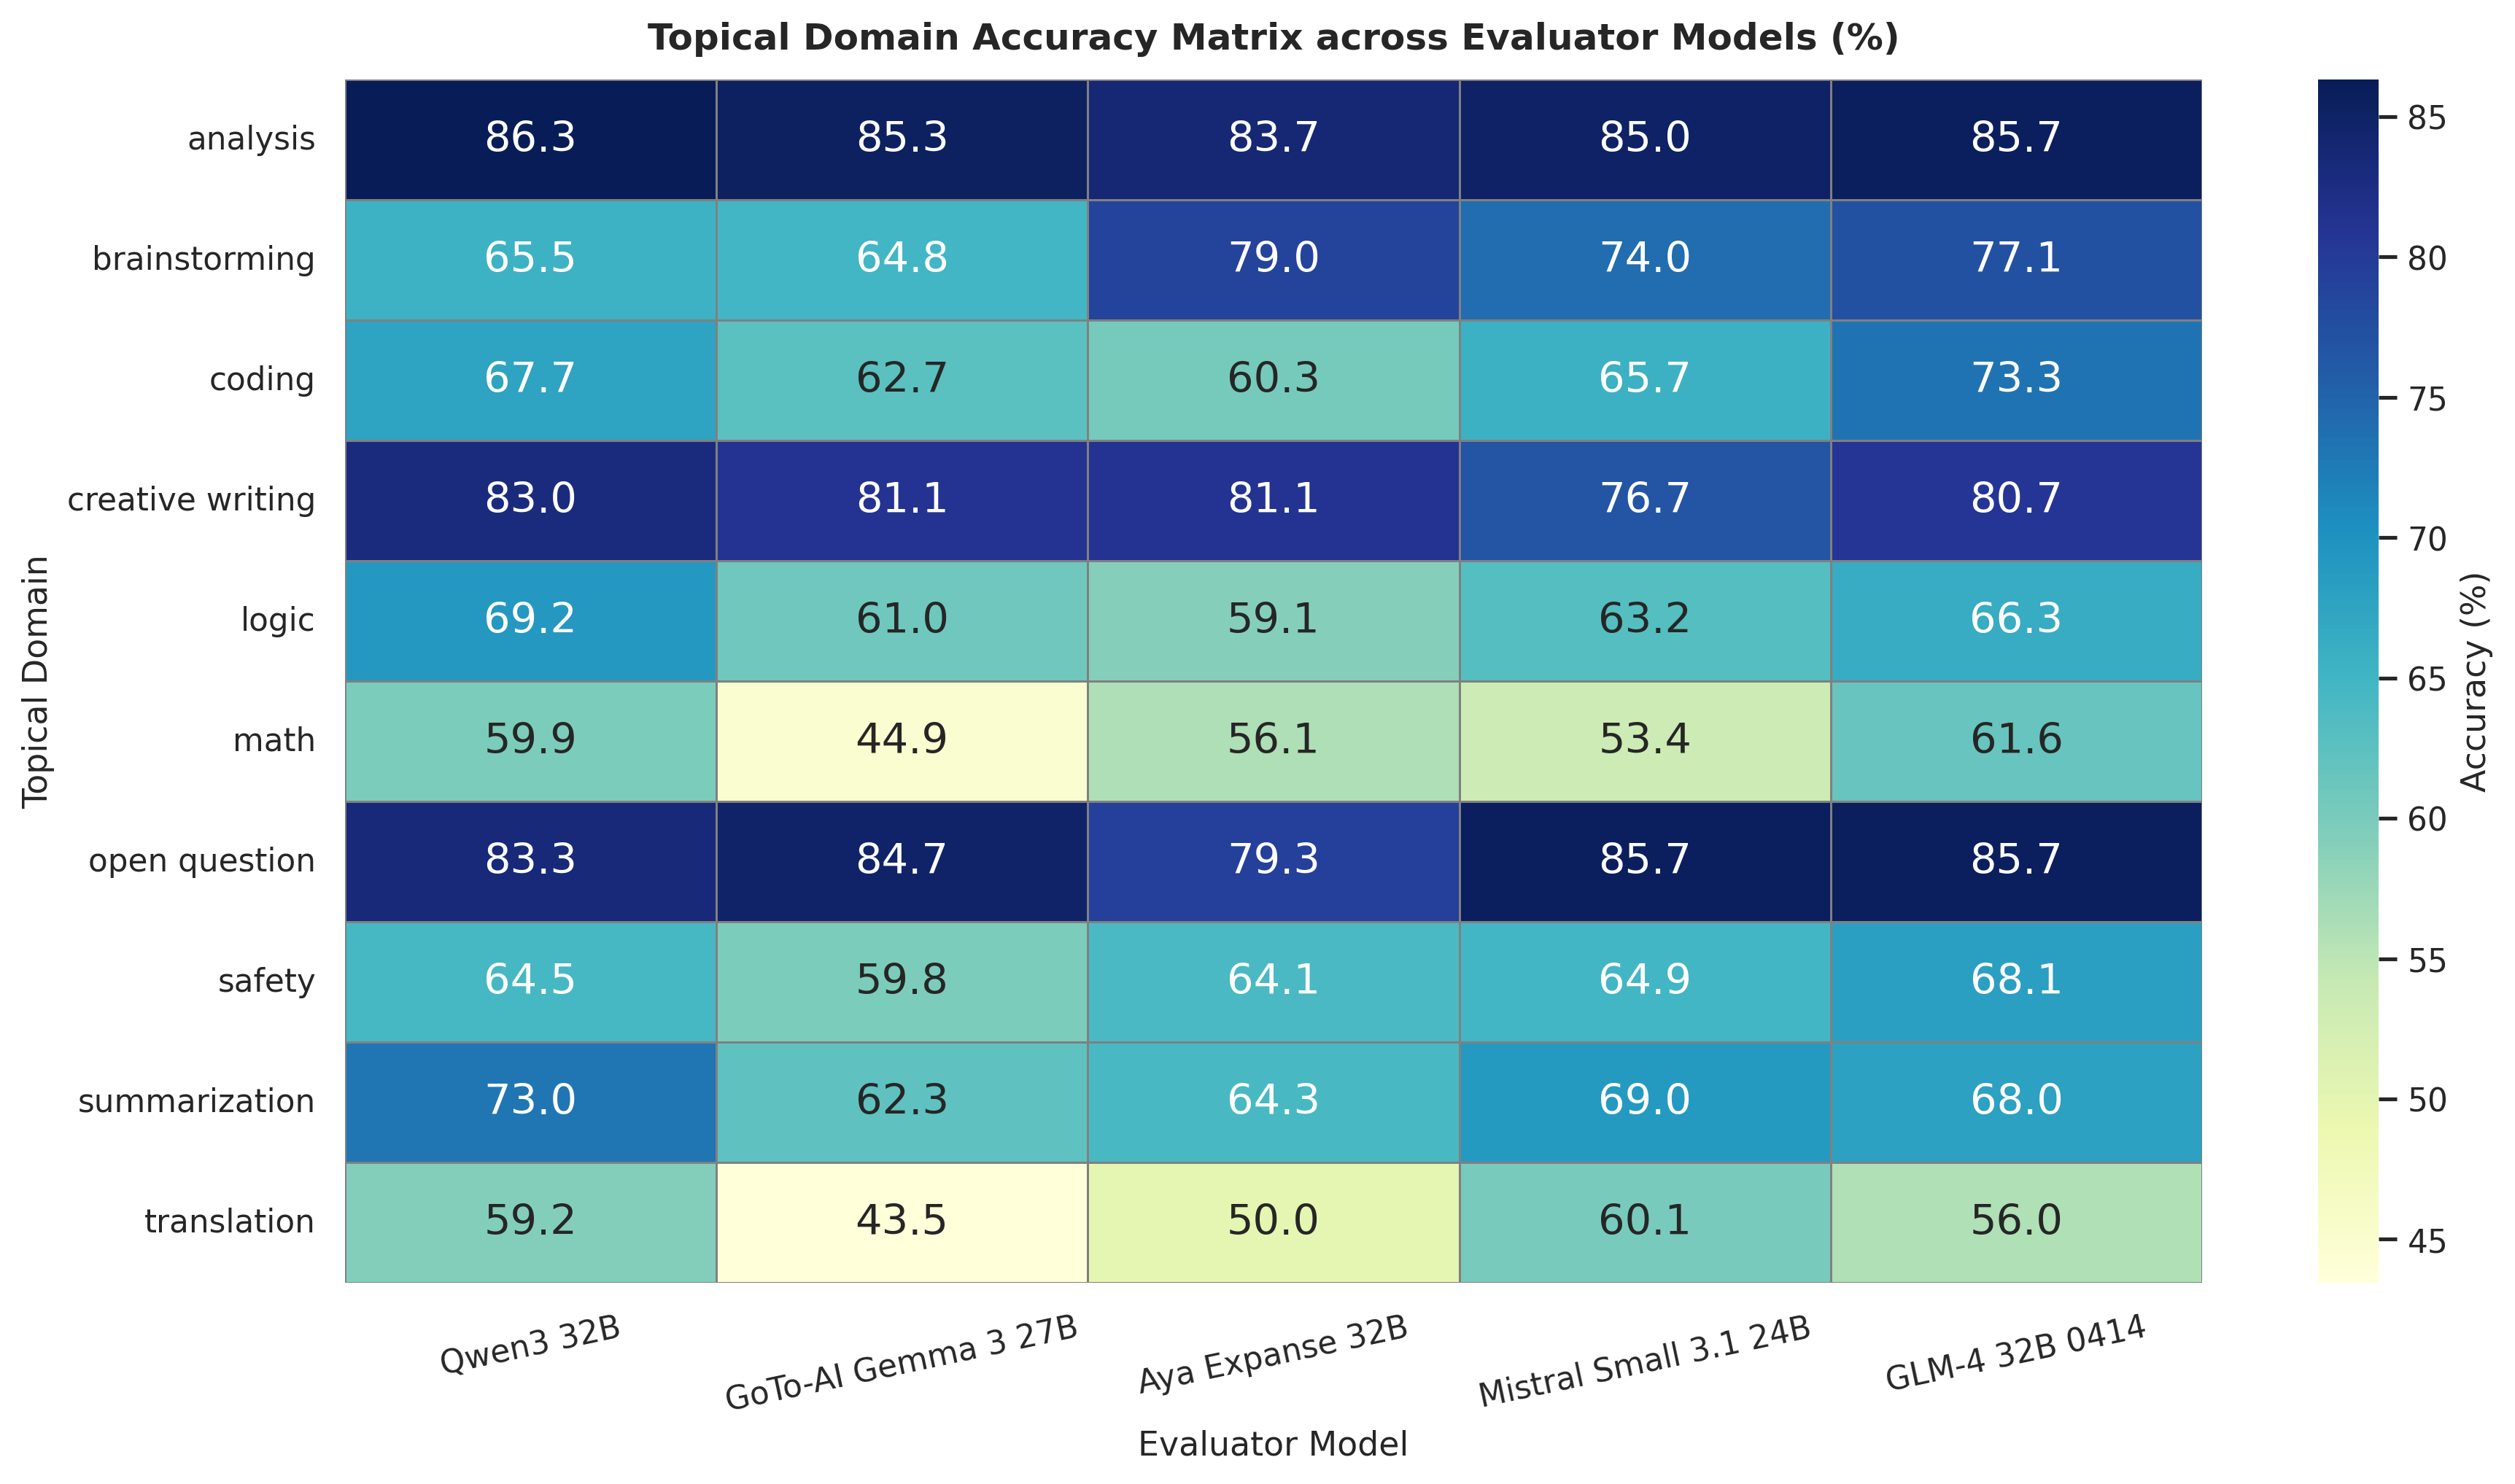

2026-11-28 07:18:45 | INFO     | llm_exp.comparison | compare_done | models=5 | path=/content/drive/MyDrive/LLMReliabilityEXP/results/comparison


,Model Key,Model,HF Repo,Is Main,Primary Strength,Precision,Evaluations (N),Valid Rate (%),Mean Accuracy (%),P1 Accuracy (%),Mean Cohen Kappa,P1 Cohen Kappa,Overall Consistency (%),Overall Flip Rate (%),First Slot Rate (%),McNemar p-value,3-Way Prompt Consistency (%)
0,qwen3_32b,Qwen3 32B,Qwen/Qwen3-32B,True,Main Baseline Model (32B),BF16,3114,100.0,70.75,72.74,0.415,0.455,67.05,32.95,65.77,8.594058e-104,84.20
1,gemma3_27b_goto,GoTo-AI Gemma 3 27B,GoToCompany/gemma3-27b-cpt-gotoai-v3-instruct,False,Indonesian Language Specialization (27B),BF16,3114,100.0,64.64,67.44,0.293,0.349,70.13,29.87,39.82,1.267343e-48,82.66
2,aya_expanse_32b,Aya Expanse 32B,CohereLabs/aya-expanse-32b,False,Multilingual Alignment (32B),BF16,3114,100.0,67.82,69.27,0.356,0.385,62.75,37.25,60.92,5.318756e-45,76.88
3,mistral_small_3_1_24b,Mistral Small 3.1 24B,mistralai/Mistral-Small-3.1-24B-Instruct-2503,False,Instruction Following (24B),BF16,3114,100.0,69.78,71.68,0.396,0.434,71.68,28.32,50.61,3.913659e-01,75.34
4,glm_4_32b,GLM-4 32B 0414,zai-org/GLM-4-32B-0414,False,Comparable 32B Reasoning Family (BF16 Parity),BF16,3114,100.0,72.19,73.89,0.444,0.478,76.11,23.89,52.57,4.204240e-05,83.04


,Qwen3 32B,GoTo-AI Gemma 3 27B,Aya Expanse 32B,Mistral Small 3.1 24B,GLM-4 32B 0414
domain,,,,,
analysis,86.33,85.33,83.67,85.00,85.67
brainstorming,65.48,64.76,79.05,74.05,77.14
coding,67.67,62.67,60.33,65.67,73.33
creative writing,82.96,81.11,81.11,76.67,80.74
logic,69.18,61.01,59.12,63.21,66.35
math,59.86,44.90,56.12,53.40,61.56
open question,83.33,84.67,79.33,85.67,85.67
safety,64.49,59.78,64.13,64.86,68.12
summarization,73.00,62.33,64.33,69.00,68.00


In [12]:
execute_comparison(
    env_file=str(ENV_FILE),
    recompute_from_jsonl=RECOMPUTE_COMPARISON,
    show_inline=SHOW_INLINE,
)

summary_csv = paths.comparison_dir / cfg.artifacts.comparison_summary_csv
domain_csv = paths.comparison_dir / cfg.artifacts.comparison_domain_accuracy_csv

display(pd.read_csv(summary_csv))
if domain_csv.is_file():
    display(pd.read_csv(domain_csv, index_col=0))